In [1]:
import pyodbc
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression,LassoLarsIC
from sklearn.preprocessing import StandardScaler,RobustScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error,f1_score, confusion_matrix,roc_auc_score,precision_score, recall_score,average_precision_score,median_absolute_error,mean_absolute_percentage_error
from sklearn.model_selection import train_test_split,StratifiedGroupKFold,GroupKFold, cross_val_predict
from sklearn.feature_selection import mutual_info_regression
import optuna
from scipy.stats import kurtosis
import shap
from sklearn.pipeline import Pipeline
from sklearn.linear_model import HuberRegressor, Ridge , ElasticNet
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, HistGradientBoostingRegressor,RandomForestClassifier
from sklearn.preprocessing import RobustScaler
from xgboost import XGBRegressor,XGBClassifier
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor,LGBMClassifier
import joblib
pd.set_option('display.float_format', lambda x: f'{x:,.2f}') 

In [5]:
conn = pyodbc.connect(
    'DRIVER={SQL Server};'
    'SERVER=LAPTOP\SQLEXPRESS;'
    'DATABASE=paie_db;'
    'Trusted_Connection=yes;'
)

df = pd.read_sql('SELECT * FROM paie_pivot', conn)

<>:3: SyntaxWarning: invalid escape sequence '\S'
<>:3: SyntaxWarning: invalid escape sequence '\S'
C:\Users\abdou\AppData\Local\Temp\ipykernel_24812\30331869.py:3: SyntaxWarning: invalid escape sequence '\S'
  'SERVER=LAPTOP\SQLEXPRESS;'
C:\Users\abdou\AppData\Local\Temp\ipykernel_24812\30331869.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql('SELECT * FROM paie_pivot', conn)


In [6]:
df.columns

Index(['csal_nosal', 'DATE', 'ETP pour égalité F/H', 'Brut partiel 2',
       'Prime Exceptionnelle', 'Valeur trentième', 'Prime d'éloignement',
       'Transport', 'Cumul libre 50', 'Cumul libre 44',
       'Net à payer sur la banque 1', 'Reconstitution Net av saisie',
       'Présence', 'Solde congé', 'Cumul libre 51',
       'Congés acquis dans le mois', 'Heures Supplementaire  65%',
       'Coût total salarial', 'Total des heures de présence',
       'Total des heures travaillées', 'Brut pour 13eme mois',
       'P. Journaliers', 'Cumul libre 47', 'Avance sur salaires Prestatair',
       'Logement', 'Cumul libre 53', 'Net social (Bulletin)',
       'Plafond théorique du salarié', 'ETP (Equivalent Temps Plein)',
       'Net à payer avec calcul impôt', 'Jour Férié 100%',
       'Assiette de la CSG 1', 'Rappel Salaire en Plus',
       'Tot Cotisation Salariale', 'Heures supplémentaires 60%',
       'Salaire horaire', 'Jours Travaillés', 'Assiette RDS 1', 'Net à payer',
       'Total c

In [7]:
df["DATE"].value_counts().sort_index() 

DATE
2023-08-31    350
2023-09-30    419
2023-10-31    531
2023-11-30    571
2023-12-31    594
2024-01-31    594
2024-02-29    601
2024-03-31    600
2024-04-30    589
2024-05-31    578
2024-06-30    563
2024-07-31    556
2024-08-31    608
2024-09-30    602
2024-10-31    582
2024-11-30    571
2024-12-31    558
2025-01-31    567
2025-02-28    556
2025-03-31    547
2025-04-30    540
2025-05-31    537
2025-06-30    531
2025-07-31    488
2025-08-31    484
2025-09-30    478
2025-10-31    351
2025-11-30    238
2025-12-31    235
2026-01-31    229
2026-02-01      1
2026-02-04      1
2026-02-14      1
2026-02-20      1
2026-02-25      1
2026-02-26      1
2026-02-28    372
Name: count, dtype: int64

In [8]:
df_test_an=df[(df["DATE"]=="2026-01-31") | (df["DATE"]=="2026-02-28") | (df["DATE"]=="2026-02-01") | (df["DATE"]=="2026-02-04") | (df["DATE"]=="2026-02-14") | (df["DATE"]=="2026-02-20") | (df["DATE"]=="2026-02-25") | (df["DATE"]=="2026-02-26") ]

In [9]:
df_test_an.to_csv("df_test.csv",index=False)

In [10]:
df_test_an.value_counts().sort_index() 

Series([], Name: count, dtype: int64)

In [11]:
df=df[(df["DATE"]!="2026-01-31") & (df["DATE"]!="2026-02-28") & (df["DATE"]!="2026-02-01") & (df["DATE"]!="2026-02-04") & (df["DATE"]!="2026-02-14") & (df["DATE"]!="2026-02-20") & (df["DATE"]!="2026-02-25") & (df["DATE"]!="2026-02-26") ]

In [12]:
df["DATE"].value_counts().sort_index()

DATE
2023-08-31    350
2023-09-30    419
2023-10-31    531
2023-11-30    571
2023-12-31    594
2024-01-31    594
2024-02-29    601
2024-03-31    600
2024-04-30    589
2024-05-31    578
2024-06-30    563
2024-07-31    556
2024-08-31    608
2024-09-30    602
2024-10-31    582
2024-11-30    571
2024-12-31    558
2025-01-31    567
2025-02-28    556
2025-03-31    547
2025-04-30    540
2025-05-31    537
2025-06-30    531
2025-07-31    488
2025-08-31    484
2025-09-30    478
2025-10-31    351
2025-11-30    238
2025-12-31    235
Name: count, dtype: int64

In [13]:
df.shape

(15019, 96)

In [14]:
df.to_csv("data_paie.csv", index=False)

In [15]:
df.head()

,csal_nosal,DATE,ETP pour égalité F/H,Brut partiel 2,Prime Exceptionnelle,Valeur trentième,Prime d'éloignement,Transport,Cumul libre 50,Cumul libre 44,...,Rappel -Heures supplément.65%,P. Responsabilité,Absence non justifié,Total des heures rémunérées,Bonus,Solde Congés,Indem Fin Contrat,Prorata Renumeration precedent,Horaire hebdomadaire,Cumul libre 43
0,53,2023-10-31,NaN,"87,105.00",NaN,22.00,NaN,"190,000.00",NaN,NaN,...,NaN,NaN,NaN,173.33,NaN,NaN,NaN,NaN,NaN,NaN
1,424,2025-07-31,NaN,"116,367.00",NaN,22.00,NaN,"346,687.50",NaN,NaN,...,NaN,NaN,1.00,173.33,NaN,NaN,NaN,NaN,NaN,NaN
3,590,2025-08-31,1.00,"89,212.00",NaN,20.00,NaN,"346,687.50",NaN,NaN,...,NaN,NaN,NaN,173.33,NaN,NaN,NaN,NaN,NaN,NaN
4,147,2024-08-31,NaN,"130,380.00",NaN,21.00,NaN,"322,500.00",NaN,NaN,...,NaN,NaN,NaN,173.33,NaN,NaN,NaN,NaN,NaN,NaN
5,514,2024-12-31,NaN,"103,258.00",NaN,21.00,NaN,"322,500.00",NaN,NaN,...,NaN,NaN,NaN,173.33,"100,000.00",NaN,NaN,NaN,NaN,NaN


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15019 entries, 0 to 15625
Data columns (total 96 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   csal_nosal                      15019 non-null  int64  
 1   DATE                            15019 non-null  object 
 2   ETP pour égalité F/H            2554 non-null   float64
 3   Brut partiel 2                  14143 non-null  float64
 4   Prime Exceptionnelle            1 non-null      float64
 5   Valeur trentième                14984 non-null  float64
 6   Prime d'éloignement             29 non-null     float64
 7   Transport                       13930 non-null  float64
 8   Cumul libre 50                  1 non-null      float64
 9   Cumul libre 44                  1 non-null      float64
 10  Net à payer sur la banque 1     15018 non-null  float64
 11  Reconstitution Net av saisie    10146 non-null  float64
 12  Présence                        15015

In [17]:
df.describe()

,csal_nosal,ETP pour égalité F/H,Brut partiel 2,Prime Exceptionnelle,Valeur trentième,Prime d'éloignement,Transport,Cumul libre 50,Cumul libre 44,Net à payer sur la banque 1,...,Rappel -Heures supplément.65%,P. Responsabilité,Absence non justifié,Total des heures rémunérées,Bonus,Solde Congés,Indem Fin Contrat,Prorata Renumeration precedent,Horaire hebdomadaire,Cumul libre 43
count,"15,019.00","2,554.00","14,143.00",1.00,"14,984.00",29.00,"13,930.00",1.00,1.00,"15,018.00",...,57.00,860.00,"1,974.00","15,015.00","1,673.00",415.00,313.00,15.00,787.00,1.00
mean,379.37,1.00,"257,744.73","3,300,000.00",20.48,"1,206,896.55","365,024.39","8,607.61","8,607.61","5,942,991.56",...,11.12,"1,125,000.00",4.59,175.29,"216,554.34","5,155,200.08","4,985,344.59","4,442.31",40.00,"8,607.61"
std,220.64,0.00,"521,816.10",NaN,2.88,"412,250.82","215,285.20",NaN,NaN,"7,052,165.39",...,6.79,"672,780.70",6.37,14.79,"586,342.02","4,864,317.23","1,843,257.82","1,091.60",0.00,NaN
min,1.00,1.00,898.00,"3,300,000.00",1.00,"1,000,000.00","75,000.00","8,607.61","8,607.61","113,024.00",...,1.00,"500,000.00",1.00,1.00,"29,000.00","80,260.47","204,030.00","1,733.00",40.00,"8,607.61"
25%,191.00,1.00,"83,665.00","3,300,000.00",20.00,"1,000,000.00","300,000.00","8,607.61","8,607.61","3,239,901.00",...,8.00,"1,000,000.00",1.00,173.33,"100,000.00","2,540,207.69","3,772,446.75","4,267.00",40.00,"8,607.61"
50%,370.00,1.00,"123,216.00","3,300,000.00",21.00,"1,000,000.00","322,500.00","8,607.61","8,607.61","3,960,713.50",...,8.00,"1,000,000.00",2.00,173.33,"100,000.00","3,826,253.29","4,924,938.35","4,267.00",40.00,"8,607.61"
75%,548.00,1.00,"225,563.00","3,300,000.00",22.00,"1,000,000.00","346,687.50","8,607.61","8,607.61","5,447,769.25",...,12.50,"1,000,000.00",4.00,173.33,"100,000.00","6,029,647.16","5,964,751.99","5,000.00",40.00,"8,607.61"
max,843.00,1.00,"25,083,425.00","3,300,000.00",23.00,"2,000,000.00","2,500,000.00","8,607.61","8,607.61","115,033,700.00",...,36.50,"5,000,000.00",30.00,240.00,"7,445,606.00","44,805,964.00","15,703,581.08","6,666.67",40.00,"8,607.61"


In [18]:
df.isnull().sum()

csal_nosal                            0
DATE                                  0
ETP pour égalité F/H              12465
Brut partiel 2                      876
Prime Exceptionnelle              15018
                                  ...  
Solde Congés                      14604
Indem Fin Contrat                 14706
Prorata Renumeration precedent    15004
Horaire hebdomadaire              14232
Cumul libre 43                    15018
Length: 96, dtype: int64

# Dimensionnality reduction / Feature Selection
### Step 1. Removing constant columns 
These are columns where every single employee has the exact same value . Because they have zero variance, they provide no information for a model to learn from and can safely be dropped ,but these columns could be special bo,uses for some employees so an abnormal salary can be justified with these columns available .

In [19]:

constant_cols = [col for col in df.columns if df[col].nunique(dropna=True) <= 1]

# 2. Identify "Quasi-Constant" columns (e.g., 99% of people have the same value)
# This helps find things like a "Tax Rate" that applie s to everyone but one person.
quasi_constant_cols = []
for col in df.columns:
    if col not in constant_cols:
        # Get the percentage of the most frequent value
        predominant_value_pct = df[col].value_counts(normalize=True,dropna=False).iloc[0]
        if predominant_value_pct > 0.97: # 99% threshold
            quasi_constant_cols.append(col)

print(f"Total Constant Columns: {len(constant_cols)}")
print(f"Columns to Drop: {constant_cols}")
print(f"Total Quasi-Constant: {len(quasi_constant_cols)}")
print(f"Quasi-Constant (99%+ same): {quasi_constant_cols}")


Total Constant Columns: 24
Columns to Drop: ['ETP pour égalité F/H', 'Prime Exceptionnelle', 'Cumul libre 50', 'Cumul libre 44', 'Cumul libre 51', 'Congés acquis dans le mois', 'Cumul libre 47', 'Cumul libre 53', 'ETP (Equivalent Temps Plein)', 'Cumul libre 45', 'Cumul libre 48', 'Sursal', 'Total congés acquis du mois', 'Plafond mensuel sécurité soc.', 'Rappel en moins', "Prime d'astreinte", 'Cumul libre 52', 'Cumul libre 46', 'TAUXSALHEURE', 'Cumul libre 54', 'Historisation SMIC horaire', 'Nombre de jours Préavis', 'Horaire hebdomadaire', 'Cumul libre 43']
Total Quasi-Constant: 20
Quasi-Constant (99%+ same): ["Prime d'éloignement", 'Solde congé', 'P. Journaliers', 'Avance sur salaires Prestatair', 'Jour Férié 100%', 'Rappel Salaire en Plus', 'Jours Travaillés', 'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%', 'Remboursement trop perçu', 'Frais Medicaux', 'Divers Prêts', 'Commission Commerciaux', 'Heures Majorée 20%', 'Acompte sur Salaire', "Rappel Prime d'ancienneté", 

In [20]:
# Inspecter chaque colonne "prime spéciale" avant de décider
for col in constant_cols:
    non_zero = df[col][df[col] != 0].dropna() 
    print(f"\n {col}")
    print(f"   Employés concernés : {len(non_zero)} / {len(df)}")
    print(f"   Valeurs : min={non_zero.min()}, max={non_zero.max()}, mean={non_zero.mean():.0f}")


 ETP pour égalité F/H
   Employés concernés : 2554 / 15019
   Valeurs : min=1.0, max=1.0, mean=1

 Prime Exceptionnelle
   Employés concernés : 1 / 15019
   Valeurs : min=3300000.0, max=3300000.0, mean=3300000

 Cumul libre 50
   Employés concernés : 1 / 15019
   Valeurs : min=8607.61, max=8607.61, mean=8608

 Cumul libre 44
   Employés concernés : 1 / 15019
   Valeurs : min=8607.61, max=8607.61, mean=8608

 Cumul libre 51
   Employés concernés : 1 / 15019
   Valeurs : min=8607.61, max=8607.61, mean=8608

 Congés acquis dans le mois
   Employés concernés : 15018 / 15019
   Valeurs : min=2.5, max=2.5, mean=2

 Cumul libre 47
   Employés concernés : 1 / 15019
   Valeurs : min=8607.61, max=8607.61, mean=8608

 Cumul libre 53
   Employés concernés : 1 / 15019
   Valeurs : min=8607.61, max=8607.61, mean=8608

 ETP (Equivalent Temps Plein)
   Employés concernés : 2554 / 15019
   Valeurs : min=1.0, max=1.0, mean=1

 Cumul libre 45
   Employés concernés : 1 / 15019
   Valeurs : min=8607.61, m

In [21]:
cols_to_drop = [
    col for col in constant_cols 
    if col.startswith("Cumul libre")
] + [
    "Congés acquis dans le mois",
    "Total congés acquis du mois", 
    "Historisation SMIC horaire",
    "ETP pour égalité F/H",
    "Plafond mensuel sécurité soc.", 
    "Horaire hebdomadaire",
    "TAUXSALHEURE"
    
]

print(f"Colonnes supprimées : {len(cols_to_drop)}")
df_reduced=df.drop(columns=cols_to_drop)
print(df_reduced.shape)

Colonnes supprimées : 18
(15019, 78)


Supression des colonnes doubles "ETP pour égalité F/H" meme que ETP (Equivalent Temps Plein) suppression des colonnes qui apportent aucune valeur et qui ont la meme valeur pout tout les employés  "Congés acquis dans le mois","Total congés acquis du mois","Historisation SMIC horaire", "Plafond mensuel sécurité soc." + les colonnes "Cumul libre qui disent rien" et Horaire hebdomaire ou il ya des autres colonnes qui donnt la meme infomation que Horaire hebdomaire

## Step 2.Similar columns 

Let's check for different columns that have the same values (similar columns) to keep only one (we will drop the columns based on which has more null values)

In [22]:
def find_similar_columns(df):
    similar_pairs = []
    
    cols = df.columns
    for i in range(len(cols)):
        col_1 = cols[i]
        series_1 = df[col_1]
        
        for col_2 in cols[i + 1:]:
            series_2 = df[col_2]
            
            # Find rows where BOTH are not null
            common_idx = series_1.notna() & series_2.notna()
            
            # If they have no common non-null rows, skip
            if not common_idx.any():
                continue
                
            # Check if values match on common rows
            if series_1[common_idx].equals(series_2[common_idx]):
                # Also calculate how many rows matched
                match_count = common_idx.sum()
                similar_pairs.append({
                    "pair": (col_1, col_2),
                    "common_rows": match_count,
                    "col1_nulls": series_1.isna().sum(),
                    "col2_nulls": series_2.isna().sum()
                })
                
    return similar_pairs

results = find_similar_columns(df_reduced)

cols_drop =[]
for res in results:
    p1, p2 = res['pair']
    print(f"'{p1}' and '{p2}' match on {res['common_rows']} shared rows.")
    if res['col1_nulls'] > res['col2_nulls']:
        print(f" {p1} has more null values : {res['col1_nulls']} than {p2} : {res['col2_nulls']} ")
        cols_drop.append(p1)
    else : 
        cols_drop.append(p2)
        print(f" {p2} has more null values : {res['col2_nulls']} than {p1} : {res['col1_nulls']} ")

cols_drop_set=set(cols_drop)

'Brut partiel 2' and 'TOT RTS' match on 14142 shared rows.
 TOT RTS has more null values : 877 than Brut partiel 2 : 876 
'Prime d'éloignement' and 'Jours Travaillés' match on 23 shared rows.
 Prime d'éloignement has more null values : 14990 than Jours Travaillés : 14898 
'Net à payer sur la banque 1' and 'Net à payer' match on 15018 shared rows.
 Net à payer sur la banque 1 has more null values : 1 than Net à payer : 0 
'Présence' and 'Total des heures travaillées' match on 15015 shared rows.
 Total des heures travaillées has more null values : 4 than Présence : 4 
'Présence' and 'Horaire' match on 15015 shared rows.
 Horaire has more null values : 4 than Présence : 4 
'Présence' and 'Total des heures rémunérées' match on 15015 shared rows.
 Total des heures rémunérées has more null values : 4 than Présence : 4 
'Coût total salarial' and 'Assiette de la CSG 1' match on 14998 shared rows.
 Assiette de la CSG 1 has more null values : 21 than Coût total salarial : 21 
'Coût total salaria

In [23]:
print(cols_drop_set)

{'Total des heures travaillées', "Prime d'éloignement", 'Horaire', 'Net avant retenues', 'Cotisation patronale fiscale', 'Total des heures rémunérées', 'Coût total patronal', 'Commission Commerciaux', 'TOT RTS', 'Assiette RDS 1', 'Salaire de présence', 'Net à payer sur la banque 1', 'Sous total pour 13ème mois', 'Assiette de la CSG 1', 'Nombre de jours Préavis', 'Brut'}


In [24]:
df_reduced=df_reduced.drop(columns=cols_drop_set)


In [25]:
df_reduced.shape

(15019, 62)

## Feature Engineering
ona va fusionner quelques colonnes en une une seule colonne ou il ya une seule valeur non nulle par ligne pour les colonnes qui présentent des exceptions et q'ils se présentes que pour quelque employés (sparse columns)


In [26]:
df_reduced.isnull().sum()[df_reduced.isnull().sum()>0].sort_values(ascending=False) 

Rappel en moins                   15019
Sursal                            15018
Prime Exceptionnelle              15018
Prime d'astreinte                 15017
Solde congé                       15015
Divers Prêts                      15010
Prorata Renumeration precedent    15004
Frais Medicaux                    14999
Jour Férié 100%                   14999
Acompte sur Salaire               14973
Remboursement trop perçu          14970
Avance sur salaires Prestatair    14962
Rappel -Heures supplément.65%     14962
Rappel Prime d'ancienneté         14955
P. Journaliers                    14924
Jours Travaillés                  14898
Heures Majorée 20%                14892
Rappel Salaire en Plus            14867
Rappel -Heures supplément.60%     14863
Rappel Heures supplément.30%      14858
Indem Fin Contrat                 14706
Solde Congés                      14604
P. Responsabilité                 14159
Bonus                             13346
Absence non justifié              13045


In [27]:
cols_cong=['Solde congé', 'Solde Congés']
(df_reduced[cols_cong].notna().sum(axis=1) > 1).sum()

np.int64(1)

In [28]:
df_reduced['Solde Congé'] = df_reduced[cols_cong].sum(axis=1)
df_reduced = df_reduced.drop(columns=cols_cong)

In [29]:
cols_primes_performances=["Sursal", "Prime d'astreinte", "Prime Exceptionnelle", "P. Responsabilité", "Bonus", "P. Journaliers","Prime de Ramadan"]
(df_reduced[cols_primes_performances].notna().sum(axis=1) > 1).sum()

np.int64(2289)

In [30]:
cols_regularisations=["Rappel en moins", "Rappel Salaire en Plus", "Rappel Prime d'ancienneté", "Prorata Renumeration precedent", "Remboursement trop perçu"]
(df_reduced[cols_regularisations].notna().sum(axis=1) > 1).sum()

np.int64(0)

In [31]:
cols_avances_prets=["Divers Prêts", "Avance sur salaires Prestatair", "Acompte sur Salaire"]
(df_reduced[cols_avances_prets].notna().sum(axis=1) > 1).sum()

np.int64(0)

In [32]:
cols_indem_divers=["Frais Medicaux", "Jour Férié 100%"]
(df_reduced[cols_indem_divers].notna().sum(axis=1) > 1).sum() 

np.int64(0)

In [33]:
cols_to_reduce = [
    "Sursal", "Rappel en moins", "Divers Prêts", "Prime d'astreinte",
    "Prime Exceptionnelle", "P. Journaliers", "Rappel Prime d'ancienneté",
    "Avance sur salaires Prestatair", "Prorata Renumeration precedent",
    "Frais Medicaux", "Jour Férié 100%", "Remboursement trop perçu",
    "Acompte sur Salaire", "Rappel Salaire en Plus","Prime de Ramadan",
    "P. Responsabilité", "Bonus"
]

In [34]:
# Définition des groupes
groupes = {
    'Primes': ["Sursal", "Prime d'astreinte", "Prime Exceptionnelle", "P. Responsabilité", "Bonus", "P. Journaliers","Prime de Ramadan"],
    'Regularisations': ["Rappel en moins", "Rappel Salaire en Plus", "Rappel Prime d'ancienneté", "Prorata Renumeration precedent", "Remboursement trop perçu"],
    'Avances_Prets': ["Divers Prêts", "Avance sur salaires Prestatair", "Acompte sur Salaire"],
    'Indem_Divers': ["Frais Medicaux", "Jour Férié 100%"]
}

df_reduced_test=df_reduced.fillna(0)
# Application
for nom_groupe, liste_cols in groupes.items():
    # On fait la somme. Si un employé a 2 primes, elles s'additionnent (logique).
    df_reduced_test[nom_groupe] = df_reduced_test[liste_cols].sum(axis=1)

# Suppression des 18 anciennes colonnes
df_reduced_test.drop(columns=cols_to_reduce, inplace=True)


In [35]:
df_reduced_test.shape

(15019, 48)

In [36]:
df_reduced_test = df_reduced_test.replace(0, np.nan)

## Step 3. Highly Correlated columns

Parfois des colonnes peuvent etre presque identiques avec des petites différences dans le veleurs ,ou des différences sur quelques lignes ou deux colonnes fortement corréles peut dire que les colonnes peuvent etre calculés l'une a partir de l'autre .on peut vérifier cela avec la corrélation entre les colonnes .
In payroll, a correlation of 0.99 or 1.0 means the two columns provide the exact same information. Keeping both is redundant and can "bias" your anomaly detection model by giving double weight to the same data.


In [37]:
# Seuil minimum de lignes non-nulles pour considérer une corrélation valide

MIN_VALID_ROWS = 200 # à ajuster selon ton contexte
numeric_df = df_reduced_test.select_dtypes(include='number')
# Calculer la corrélation seulement si assez de valeurs communes
corr_matrix = numeric_df.corr(min_periods=MIN_VALID_ROWS).abs()

# Garder seulement le triangle supérieur
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Trouver les paires avec corrélation > 0.99
redundant_pairs = []
for col in upper_triangle.columns:
    for idx in upper_triangle.index:
        val = upper_triangle.loc[idx, col]
        if pd.isna(val) or not isinstance(val, (int, float)):
            continue
        if val > 0.92:
            # Double vérification : compter les lignes non-nulles communes
            common_non_null = numeric_df[[idx, col]].dropna().shape[0]
            if common_non_null < MIN_VALID_ROWS:
                continue  # ignorer cette paire
            redundant_pairs.append({
                'colonne_1': idx,
                'colonne_2': col,
                'correlation': round(val, 4),
                'lignes_comparées': common_non_null 
            })

df_redundant = pd.DataFrame(redundant_pairs).sort_values('correlation', ascending=False)
print(df_redundant)

                        colonne_1                      colonne_2  correlation  \
55           Brut pour 13eme mois  Brut hors primes & indemnités         1.00   
56       Tot Cotisation Salariale  Brut hors primes & indemnités         1.00   
4            Brut pour 13eme mois       Tot Cotisation Salariale         1.00   
46                 Brut partiel 2         Cotisations salariales         1.00   
36            Coût total salarial                     Coût total         1.00   
18            Coût total salarial  Brut pr DFS à compter de 2022         1.00   
37          Net social (Bulletin)                     Coût total         1.00   
42  Brut pr DFS à compter de 2022                     Coût total         1.00   
19          Net social (Bulletin)  Brut pr DFS à compter de 2022         1.00   
1             Coût total salarial          Net social (Bulletin)         1.00   
3           Net social (Bulletin)  Net à payer avec calcul impôt         0.99   
29            Coût total sal

On trouves beacoups de colonnes qui sont frtement corrélés entre eux cela veut dire qu'ils sont directement calculées l'une après l'autre

In [38]:

perfect_pairs = df_redundant[df_redundant['correlation'] >0.999]
cols_drop_corr =[]
i=1
for _, row in perfect_pairs.iterrows():
    col1, col2 = row['colonne_1'], row['colonne_2']
    
    # Garder seulement les lignes où les deux colonnes sont non-nulles
    mask_non_null = df_reduced_test[col1].notna() & df_reduced_test[col2].notna()
    df_clean = df_reduced_test[mask_non_null][[col1, col2]]
    
    print(f"\n {i} -  {col1}  ↔  {col2}")
    print(f"   Lignes comparées (sans nulls) : {len(df_clean)}")
    print(f" Correlation : {row['correlation']}")
    null_values1=df_reduced_test[col1].isnull().sum()
    null_values2=df_reduced_test[col2].isnull().sum()
    if null_values1 > null_values2 :
        print(f"Nombre de valeurs nulles sur  {col1} : {null_values1} > Nombre de valeurs nulles sur  {col2} : {null_values2} ")
        
        cols_drop_corr.append(col1)
    else : 
        print(f"Nombre de valeurs nulles sur  {col2} : {null_values2} > Nombre de valeurs nulles sur  {col1} : {null_values1} ")
        cols_drop_corr.append(col2)
    
    cols_drop_corr_set=set(cols_drop_corr)
    
    mask_diff = df_clean[col1] != df_clean[col2]
    print(df_clean[mask_diff].head())
    i += 1



 1 -  Brut pour 13eme mois  ↔  Brut hors primes & indemnités
   Lignes comparées (sans nulls) : 10199
 Correlation : 1.0
Nombre de valeurs nulles sur  Brut hors primes & indemnités : 4820 > Nombre de valeurs nulles sur  Brut pour 13eme mois : 960 
   Brut pour 13eme mois  Brut hors primes & indemnités
1            267,794.00                     392,794.00
3            -83,483.00                      41,517.00
4            649,880.00                     774,880.00
5            387,599.00                     512,599.00
7            506,291.00                     631,291.00

 2 -  Tot Cotisation Salariale  ↔  Brut hors primes & indemnités
   Lignes comparées (sans nulls) : 10199
 Correlation : 1.0
Nombre de valeurs nulles sur  Brut hors primes & indemnités : 4820 > Nombre de valeurs nulles sur  Tot Cotisation Salariale : 960 
   Tot Cotisation Salariale  Brut hors primes & indemnités
1                517,794.00                     392,794.00
3                166,517.00                   

In [39]:
print(cols_drop_corr_set)    

{'Brut partiel 2', 'Coût total salarial', 'Brut pr DFS à compter de 2022', 'Brut hors primes & indemnités', 'Tot Cotisation Salariale'}


In [40]:
df_reduced_test.drop(columns=cols_drop_corr_set,inplace=True)

In [41]:
df_reduced_test.shape

(15019, 43)

In [42]:
df_reduced_test.drop(columns=[])

,csal_nosal,DATE,Valeur trentième,Transport,Reconstitution Net av saisie,Présence,Heures Supplementaire 65%,Total des heures de présence,Brut pour 13eme mois,Logement,...,Heures Majorée 20%,RETENUE MOIS 13,Rappel -Heures supplément.65%,Absence non justifié,Indem Fin Contrat,Solde Congé,Primes,Regularisations,Avances_Prets,Indem_Divers
0,53,2023-10-31,22.00,"190,000.00",NaN,173.33,NaN,173.33,"-125,000.00","276,514.00",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,424,2025-07-31,22.00,"346,687.50","176,080.00",173.33,NaN,189.33,"267,794.00","150,231.25",...,NaN,"216,714.00",NaN,1.00,NaN,NaN,"400,000.00",NaN,NaN,NaN
3,590,2025-08-31,20.00,"346,687.50","41,517.00",173.33,NaN,175.33,"-83,483.00","150,231.25",...,NaN,NaN,NaN,NaN,NaN,NaN,"400,000.00",NaN,NaN,NaN
4,147,2024-08-31,21.00,"322,500.00","245,694.00",173.33,NaN,206.33,"649,880.00","139,750.00",...,NaN,"529,186.00",NaN,NaN,NaN,NaN,"400,000.00",NaN,NaN,NaN
5,514,2024-12-31,21.00,"322,500.00","229,786.00",173.33,NaN,197.33,"387,599.00","139,750.00",...,NaN,"282,813.00",NaN,NaN,NaN,NaN,"500,000.00",NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15621,212,2025-02-28,20.00,"250,000.00",NaN,173.33,NaN,173.33,"-125,000.00","250,000.00",...,NaN,NaN,NaN,NaN,NaN,NaN,"500,000.00",NaN,NaN,NaN
15622,509,2025-05-31,19.00,NaN,NaN,240.00,NaN,240.00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,"400,000.00",NaN,NaN,NaN
15623,498,2024-02-29,21.00,NaN,NaN,240.00,NaN,240.00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15624,90,2024-05-31,19.00,"322,500.00","154,480.00",173.33,8.00,197.33,"415,681.00","139,750.00",...,NaN,"386,201.00",NaN,NaN,NaN,NaN,"1,400,000.00",NaN,NaN,NaN


In [43]:
df_reduced_test.columns

Index(['csal_nosal', 'DATE', 'Valeur trentième', 'Transport',
       'Reconstitution Net av saisie', 'Présence',
       'Heures Supplementaire  65%', 'Total des heures de présence',
       'Brut pour 13eme mois', 'Logement', 'Net social (Bulletin)',
       'Plafond théorique du salarié', 'ETP (Equivalent Temps Plein)',
       'Net à payer avec calcul impôt', 'Heures supplémentaires 60%',
       'Salaire horaire', 'Jours Travaillés', 'Net à payer',
       'Total congés acquis période', 'Historise BRUTABAT',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Net imposable', 'Heures supplémentaires 30%', 'Cotisations patronales',
       'Brut congés année en cours', 'TAUX DEVISE', 'HORAIRE MENSUEL',
       'Coût total', 'Cotisation patronale sociale', 'Cherete de vie',
       'Cotisations salariales', 'Salaire de base', 'Heures Majorée 20%',
       'RETENUE MOIS 13', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Indem Fin Contrat', 'Solde Co

il ya encore encore des colonnes corrélées entre eux mais pas directement caculés l'un aprés l'autre
on va verifier le multicolinéarité des colonnes pour détérminer les colonnes qui calculent des autres colonnes,les colonnes 100% calculées et
les colonnes sources qui contribuent a l'ensemble des colonnes calculées 

## Step 4 . Identifying Calculated columns

sparse columns do not have enough "active" rows to produce a statistically significant correlation. A correlation based on 5 shared non-zero rows out of 1000 is mathematically "real" but practically useless.
The "Zero-Correlation" Trap: If two sparse columns have zeros in the same places, they will show a high correlation (spurious correlation) simply because they share a background of nothingness.
 this algorithm might incorrectly select a sparse column as "Independent" just because it doesn't correlate with others, or it might reject it because it's "redundant" due to the zero-matching mentioned above.
That is we are calculating correlation only on dense columns and we leave sparse columns apart for now .


In [44]:
print(df_reduced_test.notnull().mean().sort_values(ascending=False)) 

csal_nosal                      1.00
DATE                            1.00
Net à payer                     1.00
Historise BRUTABAT              1.00
Coût total                      1.00
Total congés acquis période     1.00
Net à payer avec calcul impôt   1.00
Net social (Bulletin)           1.00
Total des heures de présence    1.00
Présence                        1.00
Cotisations patronales          1.00
Cotisation patronale sociale    1.00
Brut congés année en cours      1.00
Valeur trentième                1.00
Plafond théorique du salarié    1.00
Salaire horaire                 0.99
Salaire de base                 0.99
Net imposable                   0.96
Cotisations salariales          0.95
Cherete de vie                  0.94
Brut pour 13eme mois            0.94
Logement                        0.93
Transport                       0.93
Primes                          0.73
Reconstitution Net av saisie    0.68
Heures supplémentaires 30%      0.67
RETENUE MOIS 13                 0.67
H

In [45]:
sus_cols = [       
    "Total des heures de présence",
    "HORAIRE MENSUEL",
    "Historise BRUTABAT",
    "Net social (Bulletin)",
    "Coût total",
    "RETENUE MOIS 13",
    "Net à payer avec calcul impôt",
    "Brut congés année en cours",
    "Net à payer",
    "Salaire de base",
    "Net imposable",
    "Reconstitution Net av saisie",
    "Cotisations patronales",
    "Brut pour 13eme mois", 
    "Cotisations salariales",
    "Cotisation patronale sociale"  
 ]

In [46]:
df_reduced_test.columns

Index(['csal_nosal', 'DATE', 'Valeur trentième', 'Transport',
       'Reconstitution Net av saisie', 'Présence',
       'Heures Supplementaire  65%', 'Total des heures de présence',
       'Brut pour 13eme mois', 'Logement', 'Net social (Bulletin)',
       'Plafond théorique du salarié', 'ETP (Equivalent Temps Plein)',
       'Net à payer avec calcul impôt', 'Heures supplémentaires 60%',
       'Salaire horaire', 'Jours Travaillés', 'Net à payer',
       'Total congés acquis période', 'Historise BRUTABAT',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Net imposable', 'Heures supplémentaires 30%', 'Cotisations patronales',
       'Brut congés année en cours', 'TAUX DEVISE', 'HORAIRE MENSUEL',
       'Coût total', 'Cotisation patronale sociale', 'Cherete de vie',
       'Cotisations salariales', 'Salaire de base', 'Heures Majorée 20%',
       'RETENUE MOIS 13', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Indem Fin Contrat', 'Solde Co

In [47]:
#Version modifée

cols_to_drop_test = [       
    "Total des heures de présence",
    "HORAIRE MENSUEL",
    "ETP (Equivalent Temps Plein)",
    "Plafond théorique du salarié",
    "TAUX DEVISE",
    "Total congés acquis période",
    "Jours Travaillés"
     
    
 ]

In [48]:
df_test=df_reduced_test.drop(columns=cols_to_drop_test) 

In [49]:
df_test.columns

Index(['csal_nosal', 'DATE', 'Valeur trentième', 'Transport',
       'Reconstitution Net av saisie', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Net social (Bulletin)', 'Net à payer avec calcul impôt',
       'Heures supplémentaires 60%', 'Salaire horaire', 'Net à payer',
       'Historise BRUTABAT', 'Rappel Heures supplément.30%',
       'Rappel -Heures supplément.60%', 'Net imposable',
       'Heures supplémentaires 30%', 'Cotisations patronales',
       'Brut congés année en cours', 'Coût total',
       'Cotisation patronale sociale', 'Cherete de vie',
       'Cotisations salariales', 'Salaire de base', 'Heures Majorée 20%',
       'RETENUE MOIS 13', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Indem Fin Contrat', 'Solde Congé', 'Primes',
       'Regularisations', 'Avances_Prets', 'Indem_Divers'],
      dtype='object')

In [50]:
def find_calculated_columns_v2(df_original, r2_threshold=0.9, corr_threshold=0.95, min_fill_rate=0.3): 
    results = []
    cols = df_original.columns
    # ── Étape 1 : Matrice de corrélation par paires (relations directes)
    corr_matrix = df_original.corr(min_periods=int(len(df_original) * min_fill_rate)).abs()

    for target_col in cols:
        not_null_mask = df_original[target_col].notnull()
        temp_df = df_original[not_null_mask]

        if len(temp_df) < int(len(df_original) * min_fill_rate):
            results.append({
                'colonne': target_col,
                'R²': 0,
                'lignes_utilisées': len(temp_df),
                'calculée_à_partir_de': [],
            })
            continue

        if temp_df[target_col].nunique() <= 1:
            results.append({
                'colonne': target_col,
                'R²': 0,
                'lignes_utilisées': len(temp_df),
                'calculée_à_partir_de': [],
            })
            continue

        # ── Étape 2 : Trouver les colonnes DIRECTEMENT corrélées avec la cible
        if target_col in corr_matrix.columns:
            direct_corr = corr_matrix[target_col].drop(target_col).sort_values(ascending=False)
            
            # Garder seulement les colonnes fortement corrélées directement
            direct_candidates = direct_corr[direct_corr >= corr_threshold].index.tolist()
        else:
            direct_candidates = []

        # ── Étape 3 : Si pas de candidats directs, utiliser toutes les features valides
        valid_feature_cols = [
            col for col in cols
            if col != target_col
            and temp_df[col].notnull().mean() >= min_fill_rate
        ]

        # Prioriser les candidats directs pour la régression
        regression_features = direct_candidates if direct_candidates else valid_feature_cols

        if not regression_features:
            results.append({
                'colonne': target_col,
                'R²': 0,
                'lignes_utilisées': len(temp_df),
                'calculée_à_partir_de': [],
            })
            continue

        X = temp_df[regression_features].fillna(0)
        y = temp_df[target_col]

        model = LinearRegression().fit(X, y)
        score = model.score(X, y)

        if score >= r2_threshold:
            coef_map = dict(zip(X.columns, model.coef_))
            total = sum(abs(v) for v in coef_map.values())

            top_features = [
                col for col in X.columns
                if total > 0 and (abs(coef_map[col]) / total * 100) >= 5
            ]
            top_features = sorted(
                top_features,
                key=lambda c: abs(coef_map[c]),
                reverse=True
            )[:5]

            results.append({
                'colonne': target_col,
                'R²': round(score, 4),
                'lignes_utilisées': len(temp_df),
                'calculée_à_partir_de': top_features,
            })
        else:
            # ── Étape 4 : Si R² insuffisant avec candidats directs,
            #             essayer avec toutes les features valides
            if direct_candidates and len(valid_feature_cols) > len(direct_candidates):
                X_all = temp_df[valid_feature_cols].fillna(0)
                model_all = LinearRegression().fit(X_all, y)
                score_all = model_all.score(X_all, y)

                if score_all >= r2_threshold:
                    coef_map = dict(zip(X_all.columns, model_all.coef_))
                    total = sum(abs(v) for v in coef_map.values())

                    top_features = [
                        col for col in X_all.columns
                        if total > 0 and (abs(coef_map[col]) / total * 100) >= 5
                    ]
                    top_features = sorted(
                        top_features,
                        key=lambda c: abs(coef_map[c]),
                        reverse=True
                    )[:5]

    

                    results.append({
                        'colonne': target_col,
                        'R²': round(score_all, 4),
                        'lignes_utilisées': len(temp_df),
                        'calculée_à_partir_de': top_features,
                    })
                    continue

            results.append({
                'colonne': target_col,
                'R²': round(score, 4),
                'lignes_utilisées': len(temp_df),
                'calculée_à_partir_de': [],
            })

    return pd.DataFrame(results).sort_values('R²', ascending=False)


results_df2 = find_calculated_columns_v2(
    df_test.drop(columns="csal_nosal").select_dtypes(include='number'),
    r2_threshold=0.9,
    corr_threshold=0.95,   # corrélation directe minimale
    min_fill_rate=0.3
)
pd.set_option('display.max_colwidth', None)

calculated = results_df2[results_df2['R²'] >= 0.9]
independent = results_df2[results_df2['R²'] < 0.9]

print("=" * 100)
print(f"COLONNES CALCULÉES ({len(calculated)})")
print("=" * 100)
for _, row in calculated.iterrows():
    print(f"\n {row['colonne']}  (R²={row['R²']}, lignes utilisées={row['lignes_utilisées']})")
    print(f"   Principales colonnes : {', '.join(row['calculée_à_partir_de'])}")
    print("-" * 100)

print(f"\nCOLONNES INDÉPENDANTES ({len(independent)})")
print("=" * 100)
for _, row in independent.iterrows():
    print(f"   {row['colonne']:<45} R²={row['R²']:<10} lignes={row['lignes_utilisées']}")


COLONNES CALCULÉES (17)

 Reconstitution Net av saisie  (R²=1.0, lignes utilisées=10146)
   Principales colonnes : RETENUE MOIS 13, Coût total, Cotisations patronales, Brut congés année en cours
----------------------------------------------------------------------------------------------------

 Coût total  (R²=0.9996, lignes utilisées=15018)
   Principales colonnes : Historise BRUTABAT, Cotisations patronales, Net à payer, Net à payer avec calcul impôt, Net social (Bulletin)
----------------------------------------------------------------------------------------------------

 Historise BRUTABAT  (R²=0.9995, lignes utilisées=15018)
   Principales colonnes : Cotisations salariales, Net à payer, Net à payer avec calcul impôt, Net social (Bulletin)
----------------------------------------------------------------------------------------------------

 Net à payer avec calcul impôt  (R²=0.9993, lignes utilisées=15017)
   Principales colonnes : Net à payer, Historise BRUTABAT, Coût total, Co

In [51]:
df_iter = df_test.drop(columns=["csal_nosal", "Net à payer"]).select_dtypes(include='number').copy()

r2_threshold = 0.95
iteration = 1

while True:
    results_df = find_calculated_columns_v2(
        df_iter,
        r2_threshold=r2_threshold,
        corr_threshold=0.95,
        min_fill_rate=0.3
    )

    # garder seulement les colonnes calculées
    calculated = results_df[results_df['R²'] >= r2_threshold]

    if calculated.empty:
        print("\n Aucune colonne avec R² élevé restante. Fin.")
        break

    # ── Étape 1 : compter combien de fois chaque colonne est utilisée
    dependency_count = {col: 0 for col in df_iter.columns}

    for _, row in calculated.iterrows():
        for src in row['calculée_à_partir_de']:
            if src in dependency_count:
                dependency_count[src] += 1

    # ── Étape 2 : préparer les candidats
    candidates = []
    for _, row in calculated.iterrows():
        col = row['colonne']
        candidates.append({
            'col': col,
            'R2': row['R²'],
            'used_by': dependency_count[col]
        })

    # ── Étape 3 : choisir colonne à supprimer
    # priorité : R² élevé + peu utilisée
    candidates_sorted = sorted(
        candidates,
        key=lambda x: (-x['R2'], x['used_by'])
    )

    to_remove = candidates_sorted[0]['col']

    print(f"\n Itération {iteration}")
    print(f" Suppression : {to_remove}")
    print(f"   R² = {round(candidates_sorted[0]['R2'],4)} | utilisée par {candidates_sorted[0]['used_by']} colonnes")

    # (optionnel debug)
    print("   Sources :", calculated[calculated['colonne'] == to_remove]['calculée_à_partir_de'].values)

    # ── Étape 4 : suppression
    df_iter = df_iter.drop(columns=[to_remove])

    iteration += 1

print("\n Colonnes restantes :")
print(df_iter.columns.tolist()) 


 Itération 1
 Suppression : Reconstitution Net av saisie
   R² = 1.0 | utilisée par 0 colonnes
   Sources : [list(['RETENUE MOIS 13', 'Brut congés année en cours', 'Coût total', 'Cotisations patronales'])]

 Itération 2
 Suppression : Coût total
   R² = 0.9993 | utilisée par 5 colonnes
   Sources : [list(['Net social (Bulletin)', 'Historise BRUTABAT', 'Cotisations patronales'])]

 Itération 3
 Suppression : Net social (Bulletin)
   R² = 0.9943 | utilisée par 3 colonnes
   Sources : [list(['Cotisations patronales', 'Net à payer avec calcul impôt', 'Brut congés année en cours'])]

 Itération 4
 Suppression : Cotisation patronale sociale
   R² = 0.9932 | utilisée par 1 colonnes
   Sources : [list(['Valeur trentième', 'Heures supplémentaires 30%', 'Présence'])]

 Itération 5
 Suppression : Historise BRUTABAT
   R² = 0.9916 | utilisée par 2 colonnes
   Sources : [list(['Cotisations patronales', 'Cotisations salariales', 'Brut congés année en cours'])]

 Itération 6
 Suppression : RETENUE M

In [52]:
def find_direct_calculations(df_original, r2_threshold=0.9, min_fill_rate=0.3):
    df = df_original.select_dtypes(include=[np.number]).copy()
    results = []
    min_samples = int(len(df) * min_fill_rate)
    
    for target_col in df.columns:
        not_null_mask = df[target_col].notnull()
        temp_df = df[not_null_mask]
        n_valid = int(len(temp_df))
        
        if n_valid < min_samples  or temp_df[target_col].nunique() <= 1:
            results.append({
                'colonne': target_col,
                'R²': 0,
                'lignes_utilisées': n_valid,
                'statut': 'Ignorée',
                'sources_directes': []
            })
            continue

        #  Fix — garder seulement les features avec assez de vraies valeurs
        valid_feature_cols = [
            col for col in df.columns
            if col != target_col
            and temp_df[col].notnull().mean() >= min_fill_rate
        ]

        if not valid_feature_cols:
            results.append({
                'colonne': target_col,
                'R²': 0,
                'lignes_utilisées': n_valid,
                'statut': 'Features insuffisantes',
                'sources_directes': []
            })
            continue

        y = temp_df[target_col]
        X = temp_df[valid_feature_cols].fillna(0)  #  fillna(0) seulement sur features valides

        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)

        try:
            model = LassoLarsIC(criterion='bic')
            model.fit(X_scaled, y)
            score = float(model.score(X_scaled, y))
        except Exception as e:
            results.append({
                'colonne': target_col,
                'R²': 0,
                'lignes_utilisées': n_valid,
                'statut': f'Erreur: {e}',
                'sources_directes': []
            })
            continue

        if score >= r2_threshold:
            coefs = np.asarray(model.coef_)
            direct_sources = sorted(
                [valid_feature_cols[i] for i, c in enumerate(coefs) if abs(c) > 1e-5],
                key=lambda col: abs(coefs[valid_feature_cols.index(col)]),
                reverse=True
            )
            results.append({
                'colonne': target_col,
                'R²': round(score, 4),
                'lignes_utilisées': n_valid,
                'statut': ' Calculée',
                'sources_directes': direct_sources[:5]
            })
        else:
            results.append({
                'colonne': target_col,
                'R²': round(score, 4),
                'lignes_utilisées': n_valid,
                'statut': ' Indépendante',
                'sources_directes': []
            })

    return pd.DataFrame(results).sort_values('R²', ascending=False)

results_df=find_direct_calculations(df_test.drop(columns="csal_nosal"), r2_threshold=0.85)
print(results_df.to_string())

                          colonne   R²  lignes_utilisées         statut                                                                                                            sources_directes
5            Brut pour 13eme mois 1.00             14059       Calculée            [RETENUE MOIS 13, Reconstitution Net av saisie, Cotisation patronale sociale, Historise BRUTABAT, Net imposable]
2    Reconstitution Net av saisie 1.00             10146       Calculée                       [Brut pour 13eme mois, RETENUE MOIS 13, Cotisation patronale sociale, Historise BRUTABAT, Coût total]
19                     Coût total 1.00             15018       Calculée  [Brut congés année en cours, Cotisations patronales, RETENUE MOIS 13, Reconstitution Net av saisie, Net social (Bulletin)]
25                RETENUE MOIS 13 1.00             10107       Calculée          [Brut pour 13eme mois, Reconstitution Net av saisie, Cotisation patronale sociale, Historise BRUTABAT, Coût total]
7           Net soci

In [53]:
df_iter = df_test.drop(columns=["csal_nosal","Net à payer"]).select_dtypes(include='number').copy()

r2_threshold = 0.9
iteration = 1

while True:
    results_df = find_direct_calculations(
        df_iter,
        r2_threshold=r2_threshold
    )

    # garder seulement les colonnes calculées
    calculated = results_df[results_df['R²'] >= r2_threshold]

    if calculated.empty:
        print("\n Aucune colonne avec R² élevé restante. Fin.")
        break

    # ── Étape 1 : compter combien de fois chaque colonne est utilisée
    dependency_count = {col: 0 for col in df_iter.columns}

    for _, row in calculated.iterrows():
        for src in row['sources_directes']:
            if src in dependency_count:
                dependency_count[src] += 1

    # ── Étape 2 : préparer les candidats
    candidates = []
    for _, row in calculated.iterrows():
        col = row['colonne']
        candidates.append({
            'col': col,
            'R2': row['R²'],
            'used_by': dependency_count[col]
        })

    # ── Étape 3 : choisir colonne à supprimer
    # priorité : R² élevé + peu utilisée
    candidates_sorted = sorted(
        candidates,
        key=lambda x: (-x['R2'], x['used_by'])
    )

    to_remove = candidates_sorted[0]['col']

    print(f"\n Itération {iteration}")
    print(f" Suppression : {to_remove}")
    print(f"   R² = {round(candidates_sorted[0]['R2'],4)} | utilisée par {candidates_sorted[0]['used_by']} colonnes")

    # ── Étape 4 : supprimer
    df_iter = df_iter.drop(columns=[to_remove])

    iteration += 1

print("\n Colonnes restantes :")
print(df_iter.columns.tolist())


 Itération 1
 Suppression : Cotisations patronales
   R² = 1.0 | utilisée par 3 colonnes


c:\Users\abdou\PycharmProjects\payroll_salaries_anomaly_detection\venv\Lib\site-packages\sklearn\linear_model\_least_angle.py:753: ConvergenceWarning: Early stopping the lars path, as the residues are small and the current value of alpha is no longer well controlled. 31 iterations, alpha=2.011e-05, previous alpha=2.011e-05, with an active set of 18 regressors.
  warnings.warn(



 Itération 2
 Suppression : Net social (Bulletin)
   R² = 1.0 | utilisée par 3 colonnes


c:\Users\abdou\PycharmProjects\payroll_salaries_anomaly_detection\venv\Lib\site-packages\sklearn\linear_model\_least_angle.py:753: ConvergenceWarning: Early stopping the lars path, as the residues are small and the current value of alpha is no longer well controlled. 30 iterations, alpha=3.864e-05, previous alpha=3.864e-05, with an active set of 17 regressors.
  warnings.warn(



 Itération 3
 Suppression : Reconstitution Net av saisie
   R² = 1.0 | utilisée par 10 colonnes

 Itération 4
 Suppression : Coût total
   R² = 0.9998 | utilisée par 9 colonnes

 Itération 5
 Suppression : Brut congés année en cours
   R² = 0.9962 | utilisée par 7 colonnes

 Itération 6
 Suppression : Brut pour 13eme mois
   R² = 0.9943 | utilisée par 4 colonnes

 Itération 7
 Suppression : Historise BRUTABAT
   R² = 0.9931 | utilisée par 8 colonnes

 Itération 8
 Suppression : Net à payer avec calcul impôt
   R² = 0.9723 | utilisée par 6 colonnes

 Itération 9
 Suppression : Cotisations salariales
   R² = 0.9636 | utilisée par 1 colonnes

 Itération 10
 Suppression : Salaire de base
   R² = 0.9582 | utilisée par 2 colonnes

 Aucune colonne avec R² élevé restante. Fin.

 Colonnes restantes :
['Valeur trentième', 'Transport', 'Présence', 'Heures Supplementaire  65%', 'Logement', 'Heures supplémentaires 60%', 'Salaire horaire', 'Rappel Heures supplément.30%', 'Rappel -Heures supplément.

## les deux versions donnes presque les memes colonnes (seule différence est veriation de cotisations patronales) mais c'est important de garder net à payer pour detecter des anomalies dessus donc on va répéter le meme script pour un subset qui contient net a payer avec ces colonnes pour voir les colonnes qui calculent net a payer et les supprimer .

In [54]:
df_iter2 = df_iter.assign(Net_à_payer=df_reduced_test['Net à payer'])

In [55]:
df_iter2.columns

Index(['Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Logement', 'Heures supplémentaires 60%',
       'Salaire horaire', 'Rappel Heures supplément.30%',
       'Rappel -Heures supplément.60%', 'Net imposable',
       'Heures supplémentaires 30%', 'Cotisation patronale sociale',
       'Cherete de vie', 'Heures Majorée 20%', 'RETENUE MOIS 13',
       'Rappel -Heures supplément.65%', 'Absence non justifié',
       'Indem Fin Contrat', 'Solde Congé', 'Primes', 'Regularisations',
       'Avances_Prets', 'Indem_Divers', 'Net_à_payer'],
      dtype='object')

In [56]:
def find_calculated_columns_v2(df_original, r2_threshold=0.9, corr_threshold=0.95, min_fill_rate=0.3): 
    results = []
    cols = df_original.columns
    # ── Étape 1 : Matrice de corrélation par paires (relations directes)
    corr_matrix = df_original.corr(min_periods=int(len(df_original) * min_fill_rate)).abs()

    for target_col in cols:
        not_null_mask = df_original[target_col].notnull()
        temp_df = df_original[not_null_mask]

        if len(temp_df) < int(len(df_original) * min_fill_rate):
            results.append({
                'colonne': target_col,
                'R²': 0,
                'lignes_utilisées': len(temp_df),
                'calculée_à_partir_de': [],
            })
            continue

        if temp_df[target_col].nunique() <= 1:
            results.append({
                'colonne': target_col,
                'R²': 0,
                'lignes_utilisées': len(temp_df),
                'calculée_à_partir_de': [],
            })
            continue

        # ── Étape 2 : Trouver les colonnes DIRECTEMENT corrélées avec la cible
        if target_col in corr_matrix.columns:
            direct_corr = corr_matrix[target_col].drop(target_col).sort_values(ascending=False)
            
            # Garder seulement les colonnes fortement corrélées directement
            direct_candidates = direct_corr[direct_corr >= corr_threshold].index.tolist()
        else:
            direct_candidates = []

        # ── Étape 3 : Si pas de candidats directs, utiliser toutes les features valides
        valid_feature_cols = [
            col for col in cols
            if col != target_col
            and temp_df[col].notnull().mean() >= min_fill_rate
        ]

        # Prioriser les candidats directs pour la régression
        regression_features = direct_candidates if direct_candidates else valid_feature_cols

        if not regression_features:
            results.append({
                'colonne': target_col,
                'R²': 0,
                'lignes_utilisées': len(temp_df),
                'calculée_à_partir_de': [],
            })
            continue

        X = temp_df[regression_features].fillna(0)
        y = temp_df[target_col]

        model = LinearRegression().fit(X, y)
        score = model.score(X, y)

        if score >= r2_threshold:
            coef_map = dict(zip(X.columns, model.coef_))
            total = sum(abs(v) for v in coef_map.values())

            top_features = [
                col for col in X.columns
                if total > 0 and (abs(coef_map[col]) / total * 100) >= 5
            ]
            top_features = sorted(
                top_features,
                key=lambda c: abs(coef_map[c]),
                reverse=True
            )[:5]

            results.append({
                'colonne': target_col,
                'R²': round(score, 4),
                'lignes_utilisées': len(temp_df),
                'calculée_à_partir_de': top_features,
            })
        else:
            # ── Étape 4 : Si R² insuffisant avec candidats directs,
            #             essayer avec toutes les features valides
            if direct_candidates and len(valid_feature_cols) > len(direct_candidates):
                X_all = temp_df[valid_feature_cols].fillna(0)
                model_all = LinearRegression().fit(X_all, y)
                score_all = model_all.score(X_all, y)

                if score_all >= r2_threshold:
                    coef_map = dict(zip(X_all.columns, model_all.coef_))
                    total = sum(abs(v) for v in coef_map.values())

                    top_features = [
                        col for col in X_all.columns
                        if total > 0 and (abs(coef_map[col]) / total * 100) >= 5
                    ]
                    top_features = sorted(
                        top_features,
                        key=lambda c: abs(coef_map[c]),
                        reverse=True
                    )[:5]

    

                    results.append({
                        'colonne': target_col,
                        'R²': round(score_all, 4),
                        'lignes_utilisées': len(temp_df),
                        'calculée_à_partir_de': top_features,
                    })
                    continue

            results.append({
                'colonne': target_col,
                'R²': round(score, 4),
                'lignes_utilisées': len(temp_df),
                'calculée_à_partir_de': [],
            })

    return pd.DataFrame(results).sort_values('R²', ascending=False)


results_df2 = find_calculated_columns_v2(
    df_iter2.select_dtypes(include='number'),
    r2_threshold=0.9,
    corr_threshold=0.95,   # corrélation directe minimale
    min_fill_rate=0.3
)
pd.set_option('display.max_colwidth', None)

calculated = results_df2[results_df2['R²'] >= 0.9]
independent = results_df2[results_df2['R²'] < 0.9]

print("=" * 100)
print(f"COLONNES CALCULÉES ({len(calculated)})")
print("=" * 100)
for _, row in calculated.iterrows():
    print(f"\n {row['colonne']}  (R²={row['R²']}, lignes utilisées={row['lignes_utilisées']})")
    print(f"   Principales colonnes : {', '.join(row['calculée_à_partir_de'])}")
    print("-" * 100)

print(f"\nCOLONNES INDÉPENDANTES ({len(independent)})")
print("=" * 100)
for _, row in independent.iterrows():
    print(f"   {row['colonne']:<45} R²={row['R²']:<10} lignes={row['lignes_utilisées']}")


COLONNES CALCULÉES (3)

 Net_à_payer  (R²=0.9734, lignes utilisées=15019)
   Principales colonnes : Valeur trentième, Présence, Heures supplémentaires 30%, Heures Supplementaire  65%
----------------------------------------------------------------------------------------------------

 Cotisation patronale sociale  (R²=0.9651, lignes utilisées=14997)
   Principales colonnes : Valeur trentième, Présence, Heures supplémentaires 30%, Heures Supplementaire  65%
----------------------------------------------------------------------------------------------------

 Net imposable  (R²=0.9305, lignes utilisées=14432)
   Principales colonnes : Net_à_payer
----------------------------------------------------------------------------------------------------

COLONNES INDÉPENDANTES (21)
   Transport                                     R²=0.8962     lignes=13930
   RETENUE MOIS 13                               R²=0.8952     lignes=10107
   Logement                                      R²=0.845      li

In [57]:
df_iter2_linreg = df_iter2.copy()

r2_threshold = 0.95
iteration = 1

while True:
    results_df = find_calculated_columns_v2(
        df_iter2_linreg,
        r2_threshold=r2_threshold,
        corr_threshold=0.95,
        min_fill_rate=0.3
    )

    # garder seulement les colonnes calculées
    calculated = results_df[results_df['R²'] >= r2_threshold]

    if calculated.empty:
        print("\n✅ Aucune colonne avec R² élevé restante. Fin.")
        break

    # ── Étape 1 : compter combien de fois chaque colonne est utilisée
    dependency_count = {col: 0 for col in df_iter2_linreg.columns}

    for _, row in calculated.iterrows():
        for src in row['calculée_à_partir_de']:
            if src in dependency_count:
                dependency_count[src] += 1

    # ── Étape 2 : préparer les candidats
    candidates = []
    for _, row in calculated.iterrows():
        col = row['colonne']
        candidates.append({
            'col': col,
            'R2': row['R²'],
            'used_by': dependency_count[col]
        })

    # ── Étape 3 : choisir colonne à supprimer
    # priorité : R² élevé + peu utilisée
    candidates_sorted = sorted(
        candidates,
        key=lambda x: (-x['R2'], x['used_by'])
    )

    to_remove = candidates_sorted[0]['col']

    print(f"\n🔁 Itération {iteration}")
    print(f"🗑️ Suppression : {to_remove}")
    print(f"   R² = {round(candidates_sorted[0]['R2'],4)} | utilisée par {candidates_sorted[0]['used_by']} colonnes")

    # (optionnel debug)
    print("   Sources :", calculated[calculated['colonne'] == to_remove]['calculée_à_partir_de'].values)

    # ── Étape 4 : suppression
    df_iter2_linreg = df_iter2_linreg.drop(columns=[to_remove])

    iteration += 1

print("\n📊 Colonnes restantes :")
print(df_iter2_linreg.columns.tolist()) 


🔁 Itération 1
🗑️ Suppression : Net_à_payer
   R² = 0.9734 | utilisée par 0 colonnes
   Sources : [list(['Valeur trentième', 'Présence', 'Heures supplémentaires 30%', 'Heures Supplementaire  65%'])]

✅ Aucune colonne avec R² élevé restante. Fin.

📊 Colonnes restantes :
['Valeur trentième', 'Transport', 'Présence', 'Heures Supplementaire  65%', 'Logement', 'Heures supplémentaires 60%', 'Salaire horaire', 'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%', 'Net imposable', 'Heures supplémentaires 30%', 'Cotisation patronale sociale', 'Cherete de vie', 'Heures Majorée 20%', 'RETENUE MOIS 13', 'Rappel -Heures supplément.65%', 'Absence non justifié', 'Indem Fin Contrat', 'Solde Congé', 'Primes', 'Regularisations', 'Avances_Prets', 'Indem_Divers']


In [58]:
def find_direct_calculations(df_original, r2_threshold=0.9, min_fill_rate=0.3):
    df = df_original.select_dtypes(include=[np.number]).copy()
    results = []
    min_samples = int(len(df) * min_fill_rate)
    
    for target_col in df.columns:
        not_null_mask = df[target_col].notnull()
        temp_df = df[not_null_mask]
        n_valid = int(len(temp_df))
        
        if n_valid < min_samples  or temp_df[target_col].nunique() <= 1:
            results.append({
                'colonne': target_col,
                'R²': 0,
                'lignes_utilisées': n_valid,
                'statut': 'Ignorée',
                'sources_directes': []
            })
            continue

        # ✅ Fix — garder seulement les features avec assez de vraies valeurs
        valid_feature_cols = [
            col for col in df.columns
            if col != target_col
            and temp_df[col].notnull().mean() >= min_fill_rate
        ]

        if not valid_feature_cols:
            results.append({
                'colonne': target_col,
                'R²': 0,
                'lignes_utilisées': n_valid,
                'statut': 'Features insuffisantes',
                'sources_directes': []
            })
            continue

        y = temp_df[target_col]
        X = temp_df[valid_feature_cols].fillna(0)  # ✅ fillna(0) seulement sur features valides

        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)

        try:
            model = LassoLarsIC(criterion='bic')
            model.fit(X_scaled, y)
            score = float(model.score(X_scaled, y))
        except Exception as e:
            results.append({
                'colonne': target_col,
                'R²': 0,
                'lignes_utilisées': n_valid,
                'statut': f'Erreur: {e}',
                'sources_directes': []
            })
            continue

        if score >= r2_threshold:
            coefs = np.asarray(model.coef_)
            direct_sources = sorted(
                [valid_feature_cols[i] for i, c in enumerate(coefs) if abs(c) > 1e-5],
                key=lambda col: abs(coefs[valid_feature_cols.index(col)]),
                reverse=True
            )
            results.append({
                'colonne': target_col,
                'R²': round(score, 4),
                'lignes_utilisées': n_valid,
                'statut': ' Calculée',
                'sources_directes': direct_sources[:5]
            })
        else:
            results.append({
                'colonne': target_col,
                'R²': round(score, 4),
                'lignes_utilisées': n_valid,
                'statut': ' Indépendante',
                'sources_directes': []
            })

    return pd.DataFrame(results).sort_values('R²', ascending=False)

results_df=find_direct_calculations(df_iter2.select_dtypes(include='number'), r2_threshold=0.9)
print(results_df.to_string())

                          colonne   R²  lignes_utilisées         statut                                                                          sources_directes
23                    Net_à_payer 0.97             15019       Calculée  [Cotisation patronale sociale, Net imposable, Cherete de vie, Salaire horaire, Présence]
11   Cotisation patronale sociale 0.97             14997       Calculée                   [Net_à_payer, Net imposable, Cherete de vie, Salaire horaire, Logement]
9                   Net imposable 0.96             14432       Calculée          [Net_à_payer, Cotisation patronale sociale, Cherete de vie, Logement, Transport]
1                       Transport 0.90             13930   Indépendante                                                                                        []
14                RETENUE MOIS 13 0.90             10107   Indépendante                                                                                        []
4                        Log

In [59]:
df_iter2_lasso = df_iter2.copy()

r2_threshold = 0.95
iteration = 1

while True:
    results_df = find_direct_calculations(
        df_iter2_lasso,
        r2_threshold=r2_threshold
    )

    # garder seulement les colonnes calculées
    calculated = results_df[results_df['R²'] >= r2_threshold]

    if calculated.empty:
        print("\n✅ Aucune colonne avec R² élevé restante. Fin.")
        break

    # ── Étape 1 : compter combien de fois chaque colonne est utilisée
    dependency_count = {col: 0 for col in df_iter2_lasso.columns}

    for _, row in calculated.iterrows():
        for src in row['sources_directes']:
            if src in dependency_count:
                dependency_count[src] += 1

    # ── Étape 2 : préparer les candidats
    candidates = []
    for _, row in calculated.iterrows():
        col = row['colonne']
        candidates.append({
            'col': col,
            'R2': row['R²'],
            'used_by': dependency_count[col]
        })

    # ── Étape 3 : choisir colonne à supprimer
    # priorité : R² élevé + peu utilisée
    candidates_sorted = sorted(
        candidates,
        key=lambda x: (-x['R2'], x['used_by'])
    )

    to_remove = candidates_sorted[0]['col']

    print(f"\n🔁 Itération {iteration}")
    print(f"🗑️ Suppression : {to_remove}")
    print(f"   R² = {round(candidates_sorted[0]['R2'],4)} | utilisée par {candidates_sorted[0]['used_by']} colonnes")

    # ── Étape 4 : supprimer
    df_iter2_lasso = df_iter2_lasso.drop(columns=[to_remove])

    iteration += 1

print("\n📊 Colonnes restantes :")
print(df_iter2_lasso.columns.tolist())


🔁 Itération 1
🗑️ Suppression : Net_à_payer
   R² = 0.9734 | utilisée par 2 colonnes

✅ Aucune colonne avec R² élevé restante. Fin.

📊 Colonnes restantes :
['Valeur trentième', 'Transport', 'Présence', 'Heures Supplementaire  65%', 'Logement', 'Heures supplémentaires 60%', 'Salaire horaire', 'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%', 'Net imposable', 'Heures supplémentaires 30%', 'Cotisation patronale sociale', 'Cherete de vie', 'Heures Majorée 20%', 'RETENUE MOIS 13', 'Rappel -Heures supplément.65%', 'Absence non justifié', 'Indem Fin Contrat', 'Solde Congé', 'Primes', 'Regularisations', 'Avances_Prets', 'Indem_Divers']


les colonnes Cotisation patronale sociale et Net imposable sont fortement corrélés avec Net a payer donc on va les supprimer ,contexte métier ca se vérifies aussi car net imposable se dérives du Net à payer et cotisation partonale sociale est une partie 

In [60]:
#Version modifée

cols_to_drop = [       
    "Total des heures de présence",
    "HORAIRE MENSUEL",
    "Historise BRUTABAT",
    "Net social (Bulletin)",
    "Coût total",
    "RETENUE MOIS 13",
    "Net à payer avec calcul impôt",
    "Brut congés année en cours",
    "Net imposable",
    "Reconstitution Net av saisie",
    "Cotisation patronale sociale",
    "Cotisations salariales",
    "Cotisations patronales",
    "Salaire de base"
 ]

## Suppression des colonnes redondantes et calculées
Dans le cadre de la phase de prétraitement, une analyse de multicolinéarité a été conduite en combinant la régression linéaire (R²) et l'algorithme LassoLarsIC afin d'identifier les colonnes entièrement dérivées d'autres variables. Les colonnes Net social (Bulletin), Net à payer avec calcul impôt et Net imposable ont été supprimées car elles constituent des variantes comptables de Net à payer, calculées automatiquement par le système Sage avec des déductions légèrement différentes, confirmées par un R² supérieur à 0.99. Les colonnes Coût total et Brut congés année en cours forment une boucle fermée avec les cotisations patronales et ont été supprimées car elles représentent des agrégats calculés automatiquement à partir d'autres variables déjà présentes. Historise BRUTABAT a été supprimée malgré son importance métier car ses sources directes notamment Net à payer et Net social suffisent à représenter l'information du salaire brut. RETENUE MOIS 13 et Reconstitution Net av saisie participent à une chaîne de calcul circulaire avec R²=1.0, confirmant leur caractère entièrement redondant. Total des heures de présence a été supprimée car elle est la somme arithmétique de Présence et des heures supplémentaires déjà présentes dans le dataset. Salaire de base, Cotisations salariales, Cotisations patronales et Cotisation patronale sociale ont été supprimées car elles contribuent directement au calcul de Net à payer, créant une redondance qui surpondèrerait artificiellement l'information salariale dans le modèle de détection. Enfin, HORAIRE MENSUEL a été supprimée en raison qu'il ya total des heures de présence représente sle meme information .L'ensemble de ces suppressions est justifié par un double critère : statistique (R² ≥ 0.90 confirmé par les deux méthodes) et métier (relation comptable directe vérifiable dans les règles de paie Sage).

In [61]:
df_reduced_test2=df_reduced_test.drop(columns=cols_to_drop)  

In [62]:
df_reduced_test2.shape 

(15019, 29)

In [63]:
print(df_reduced_test2.notnull().count().sort_values(ascending=False)) 

csal_nosal                       15019
DATE                             15019
Valeur trentième                 15019
Transport                        15019
Présence                         15019
Heures Supplementaire  65%       15019
Brut pour 13eme mois             15019
Logement                         15019
Plafond théorique du salarié     15019
ETP (Equivalent Temps Plein)     15019
Heures supplémentaires 60%       15019
Salaire horaire                  15019
Jours Travaillés                 15019
Net à payer                      15019
Total congés acquis période      15019
Rappel Heures supplément.30%     15019
Rappel -Heures supplément.60%    15019
Heures supplémentaires 30%       15019
TAUX DEVISE                      15019
Cherete de vie                   15019
Heures Majorée 20%               15019
Rappel -Heures supplément.65%    15019
Absence non justifié             15019
Indem Fin Contrat                15019
Solde Congé                      15019
Primes                   

In [64]:
df_reduced_test2.columns

Index(['csal_nosal', 'DATE', 'Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Plafond théorique du salarié', 'ETP (Equivalent Temps Plein)',
       'Heures supplémentaires 60%', 'Salaire horaire', 'Jours Travaillés',
       'Net à payer', 'Total congés acquis période',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Heures supplémentaires 30%', 'TAUX DEVISE', 'Cherete de vie',
       'Heures Majorée 20%', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Indem Fin Contrat', 'Solde Congé', 'Primes',
       'Regularisations', 'Avances_Prets', 'Indem_Divers'],
      dtype='object')

# Residual Analysis (Detecting anomalies using regression)
### Detecting anomalies using regression involves building a model to predict expected values and identifying data points that deviate significantly from these predictions (outliers)

In [65]:
cols_to_drop_residual = [       
    "Total des heures de présence",
    "HORAIRE MENSUEL",
    "Historise BRUTABAT",
    "Net social (Bulletin)",
    "Coût total",
    "RETENUE MOIS 13",
    "Net à payer avec calcul impôt",
    "Brut congés année en cours",
    "Net imposable",
    "Reconstitution Net av saisie",
    "Cotisation patronale sociale",
    "Cotisations salariales",
    "Cotisations patronales",
    "TAUX DEVISE",
    "Plafond théorique du salarié",
    "ETP (Equivalent Temps Plein)"
 ]

In [66]:
df_reduced_res=df_reduced_test.drop(columns=cols_to_drop_residual) 

In [67]:
X_res=df_reduced_res.drop(columns=["csal_nosal","DATE"])

In [68]:
X_res.fillna(0,inplace=True)

In [69]:
X_res.shape

(15019, 25)

In [70]:
X_res.isnull().sum()[X_res.isnull().sum()>0].sort_values(ascending=False) 

Series([], dtype: int64)

In [71]:
X_res.columns

Index(['Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Heures supplémentaires 60%', 'Salaire horaire', 'Jours Travaillés',
       'Net à payer', 'Total congés acquis période',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Heures supplémentaires 30%', 'Cherete de vie', 'Salaire de base',
       'Heures Majorée 20%', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Indem Fin Contrat', 'Solde Congé', 'Primes',
       'Regularisations', 'Avances_Prets', 'Indem_Divers'],
      dtype='object')

## Checking the null values before modelisation

In [72]:
X_res_test_null=X_res.replace(0,np.nan)

In [73]:
X_res_test_null.isnull().sum()[X_res_test_null.isnull().sum()>0].sort_values(ascending=False) 

Indem_Divers                     14979
Rappel -Heures supplément.65%    14962
Avances_Prets                    14907
Jours Travaillés                 14898
Heures Majorée 20%               14892
Rappel -Heures supplément.60%    14863
Rappel Heures supplément.30%     14858
Regularisations                  14739
Indem Fin Contrat                14706
Solde Congé                      14601
Absence non justifié             13045
Heures Supplementaire  65%       10228
Heures supplémentaires 60%        5008
Heures supplémentaires 30%        4892
Primes                            4022
Transport                         1089
Logement                           985
Brut pour 13eme mois               960
Cherete de vie                     949
Salaire horaire                     86
Salaire de base                     86
Valeur trentième                    35
Présence                             4
Total congés acquis période          2
dtype: int64

In [74]:
x = X_res.drop(columns=['Net à payer'])
y = X_res['Net à payer']

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [75]:
def make_mi_scores(X, y):
    mi_scores = mutual_info_regression(X, y)
    mi_scores = pd.Series(mi_scores, name="MI Scores", index=X.columns)
    mi_scores = mi_scores.sort_values(ascending=False)
    return mi_scores

mi_scores = make_mi_scores(X_train, y_train)
print(mi_scores)

Brut pour 13eme mois            1.97
Salaire de base                 1.97
Salaire horaire                 1.90
Cherete de vie                  1.71
Logement                        1.43
Transport                       1.34
Heures supplémentaires 60%      0.89
Heures supplémentaires 30%      0.70
Primes                          0.44
Heures Supplementaire  65%      0.33
Total congés acquis période     0.28
Valeur trentième                0.22
Absence non justifié            0.20
Présence                        0.12
Solde Congé                     0.06
Indem Fin Contrat               0.05
Regularisations                 0.03
Jours Travaillés                0.02
Rappel Heures supplément.30%    0.01
Avances_Prets                   0.01
Rappel -Heures supplément.65%   0.01
Rappel -Heures supplément.60%   0.01
Heures Majorée 20%              0.00
Indem_Divers                    0.00
Name: MI Scores, dtype: float64


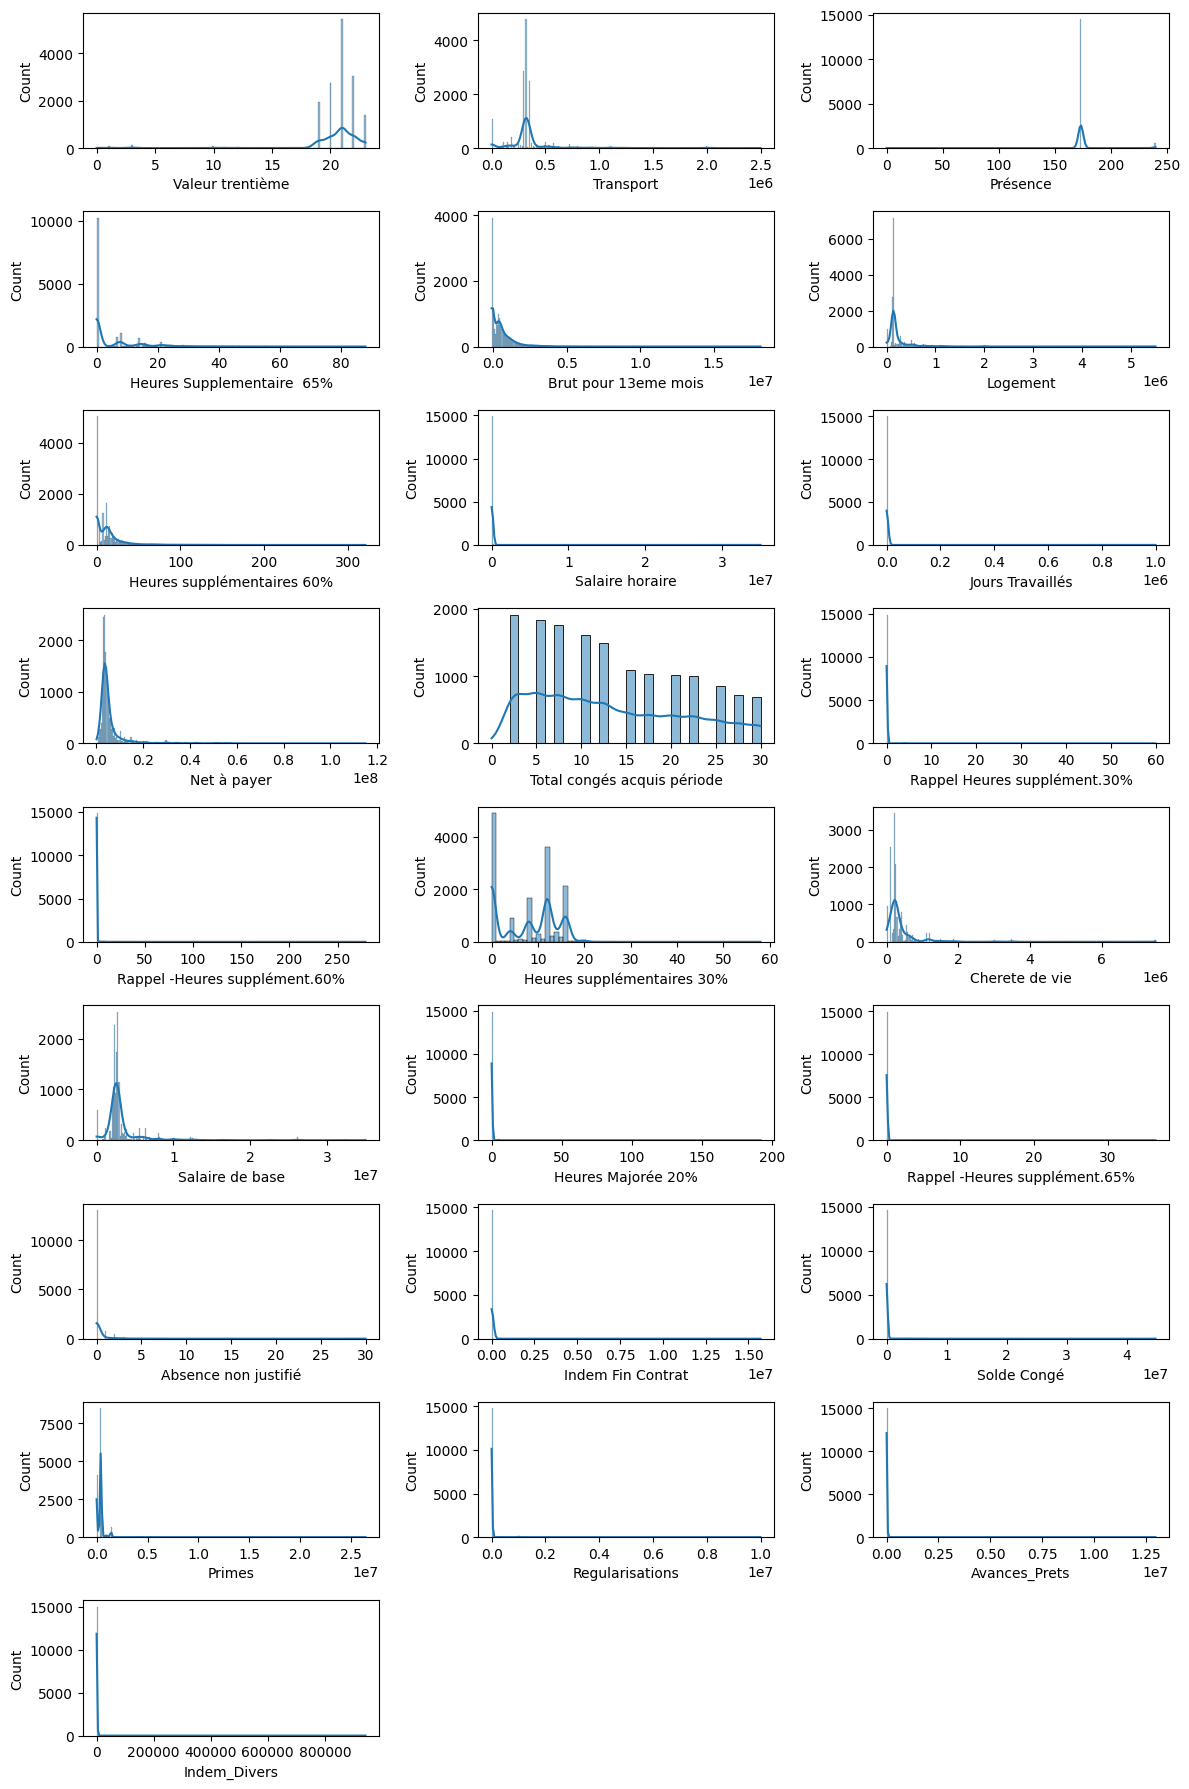

In [79]:
fig = plt.figure(figsize=(12,18))
for i in range(len(X_res.columns)):
    fig.add_subplot(9,3,i+1)
    sns.histplot(x=X_res.iloc[:,i],kde=True)

plt.tight_layout()
plt.show()

Most features are skewed and heavily influenced by outliers linear models needs sclaing(robust scaling)  
Modified z-score needs to be taken into consideration given that normal z-score will be influenced by outliers .

In [80]:
x = X_res.drop(columns=['Net à payer'])
y = X_res['Net à payer']


In [81]:
x.columns

Index(['Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Heures supplémentaires 60%', 'Salaire horaire', 'Jours Travaillés',
       'Total congés acquis période', 'Rappel Heures supplément.30%',
       'Rappel -Heures supplément.60%', 'Heures supplémentaires 30%',
       'Cherete de vie', 'Salaire de base', 'Heures Majorée 20%',
       'Rappel -Heures supplément.65%', 'Absence non justifié',
       'Indem Fin Contrat', 'Solde Congé', 'Primes', 'Regularisations',
       'Avances_Prets', 'Indem_Divers'],
      dtype='object')

In [82]:
x.columns

Index(['Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Heures supplémentaires 60%', 'Salaire horaire', 'Jours Travaillés',
       'Total congés acquis période', 'Rappel Heures supplément.30%',
       'Rappel -Heures supplément.60%', 'Heures supplémentaires 30%',
       'Cherete de vie', 'Salaire de base', 'Heures Majorée 20%',
       'Rappel -Heures supplément.65%', 'Absence non justifié',
       'Indem Fin Contrat', 'Solde Congé', 'Primes', 'Regularisations',
       'Avances_Prets', 'Indem_Divers'],
      dtype='object')

In [83]:
gb_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    min_samples_leaf=20,
    subsample=0.8,
    random_state=42
)

rf_model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=20,
    max_features=0.7,
    random_state=42
)



In [84]:
y_gb=cross_val_predict(gb_model, x, y, cv=5)
y_rf=cross_val_predict(rf_model, x, y, cv=5)

print(f"R² GB : {r2_score(y, y_gb):.4f}")
print(f"R² RF : {r2_score(y, y_rf):.4f}")
print(f"MAE GB : {mean_absolute_error(y, y_gb)}")
print(f"MAE RF : {mean_absolute_error(y, y_rf)}")
gb_residuals = y - y_gb
rf_residuals = y - y_rf


R² GB : 0.9746
R² RF : 0.9555
MAE GB : 241759.03447563222
MAE RF : 324527.5646397771


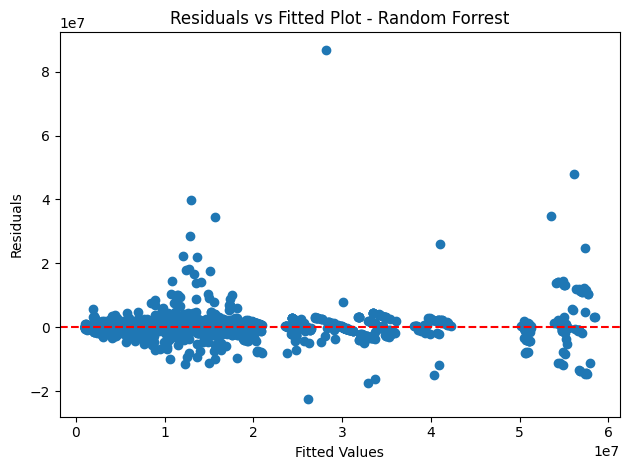

In [85]:
plt.scatter(y_rf, rf_residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title(f'Residuals vs Fitted Plot - Random Forrest')

plt.tight_layout()
plt.show()

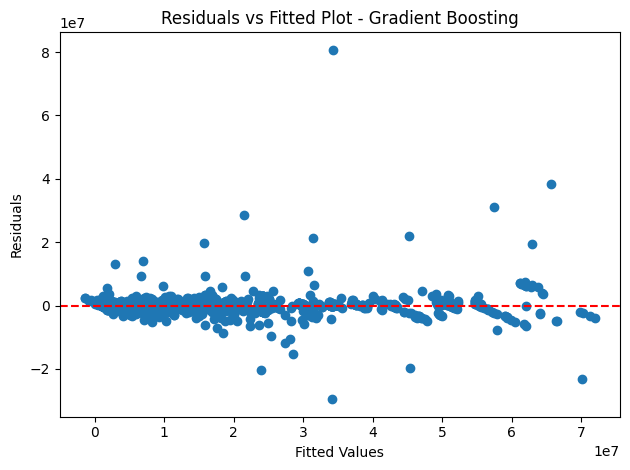

In [86]:
plt.scatter(y_gb, gb_residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title(f'Residuals vs Fitted Plot - Gradient Boosting')

plt.tight_layout()
plt.show()

In [87]:
median_res = np.median(gb_residuals)
mad_res = np.median(np.abs(gb_residuals - median_res))
gb_robust_z_score = 0.6745 * (gb_residuals - median_res) / mad_res     

median_res_rf = np.median(rf_residuals)
mad_res_rf = np.median(np.abs(rf_residuals - median_res_rf))    
rf_robust_z_score = 0.6745 * (rf_residuals - median_res_rf) / mad_res_rf


In [88]:
df_predictions=pd.DataFrame({
    'csal_nosal' : df['csal_nosal'].values,
    'DATE'       : df['DATE'].values,
    'Net à payer': y.values,
    'Pred_GB'    : y_gb,
    'Pred_RF'    : y_rf,
    'Residual_GB' : gb_residuals,
    'Residual_RF' : rf_residuals,
    'Anomaly_GB' : (gb_robust_z_score.abs() > 3.5).astype(int),
    'Anomaly_RF' : (rf_robust_z_score.abs() > 3.5).astype(int)
})

In [89]:
df_predictions_gb=pd.DataFrame({
    'csal_nosal' : df['csal_nosal'].values,
    'DATE'       : df['DATE'].values,
    'Net à payer': y.values,
    'Pred_GB'    : y_gb,
    'Residual_GB' : gb_residuals,
    'Anomaly_GB' : (gb_robust_z_score.abs() > 3.5).astype(int),
})

In [90]:
df_anomalies_residuals=df_predictions[(df_predictions['Anomaly_GB'] == 1) | (df_predictions['Anomaly_RF'] == 1)]

In [91]:
df_reduced_res.drop(columns=['Net à payer'])

,csal_nosal,DATE,Valeur trentième,Transport,Présence,Heures Supplementaire 65%,Brut pour 13eme mois,Logement,Heures supplémentaires 60%,Salaire horaire,...,Salaire de base,Heures Majorée 20%,Rappel -Heures supplément.65%,Absence non justifié,Indem Fin Contrat,Solde Congé,Primes,Regularisations,Avances_Prets,Indem_Divers
0,53,2023-10-31,22.00,"190,000.00",173.33,NaN,"-125,000.00","276,514.00",NaN,"16,541.31",...,"2,867,105.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,424,2025-07-31,22.00,"346,687.50",173.33,NaN,"267,794.00","150,231.25",8.00,"16,930.80",...,"2,934,615.63",NaN,NaN,1.00,NaN,NaN,"400,000.00",NaN,NaN,NaN
3,590,2025-08-31,20.00,"346,687.50",173.33,NaN,"-83,483.00","150,231.25",NaN,"15,967.93",...,"2,767,721.88",NaN,NaN,NaN,NaN,NaN,"400,000.00",NaN,NaN,NaN
4,147,2024-08-31,21.00,"322,500.00",173.33,NaN,"649,880.00","139,750.00",21.00,"15,749.58",...,"2,729,875.43",NaN,NaN,NaN,NaN,NaN,"400,000.00",NaN,NaN,NaN
5,514,2024-12-31,21.00,"322,500.00",173.33,NaN,"387,599.00","139,750.00",12.00,"14,729.85",...,"2,553,125.00",NaN,NaN,NaN,NaN,NaN,"500,000.00",NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15621,212,2025-02-28,20.00,"250,000.00",173.33,NaN,"-125,000.00","250,000.00",NaN,"20,768.31",...,"3,599,772.00",NaN,NaN,NaN,NaN,NaN,"500,000.00",NaN,NaN,NaN
15622,509,2025-05-31,19.00,NaN,240.00,NaN,NaN,NaN,NaN,10.42,...,"2,500.00",NaN,NaN,NaN,NaN,NaN,"400,000.00",NaN,NaN,NaN
15623,498,2024-02-29,21.00,NaN,240.00,NaN,NaN,NaN,NaN,27.08,...,"6,500.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15624,90,2024-05-31,19.00,"322,500.00",173.33,8.00,"415,681.00","139,750.00",8.00,"14,853.89",...,"2,574,625.00",NaN,NaN,NaN,NaN,NaN,"1,400,000.00",NaN,NaN,NaN


In [92]:
anomalies_residuals=df_anomalies_residuals.merge(df_reduced_res, on=['csal_nosal', 'DATE'], how='inner')

In [93]:
anomalies_residuals.drop(columns=['Net à payer_x'], inplace=True) 

In [94]:
anomalies_residuals.columns

Index(['csal_nosal', 'DATE', 'Pred_GB', 'Pred_RF', 'Residual_GB',
       'Residual_RF', 'Anomaly_GB', 'Anomaly_RF', 'Valeur trentième',
       'Transport', 'Présence', 'Heures Supplementaire  65%',
       'Brut pour 13eme mois', 'Logement', 'Heures supplémentaires 60%',
       'Salaire horaire', 'Jours Travaillés', 'Net à payer_y',
       'Total congés acquis période', 'Rappel Heures supplément.30%',
       'Rappel -Heures supplément.60%', 'Heures supplémentaires 30%',
       'Cherete de vie', 'Salaire de base', 'Heures Majorée 20%',
       'Rappel -Heures supplément.65%', 'Absence non justifié',
       'Indem Fin Contrat', 'Solde Congé', 'Primes', 'Regularisations',
       'Avances_Prets', 'Indem_Divers'],
      dtype='object')

Une analyse de faux positifs et performance du modele  été effectiué sur quelque échentillons (voir le rapport d'avancement) on va essayer de segmneter les cas anormales a l'aide de kmeans pour voir tous le cas et predre des echantillons de chaque segmet pour analyser les faux positifs 

In [95]:
anomalies_residuals=df_anomalies_residuals.merge(df_reduced_res, on=['csal_nosal', 'DATE'], how='inner')

In [96]:
anomalies_residuals.columns

Index(['csal_nosal', 'DATE', 'Net à payer_x', 'Pred_GB', 'Pred_RF',
       'Residual_GB', 'Residual_RF', 'Anomaly_GB', 'Anomaly_RF',
       'Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Heures supplémentaires 60%', 'Salaire horaire', 'Jours Travaillés',
       'Net à payer_y', 'Total congés acquis période',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Heures supplémentaires 30%', 'Cherete de vie', 'Salaire de base',
       'Heures Majorée 20%', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Indem Fin Contrat', 'Solde Congé', 'Primes',
       'Regularisations', 'Avances_Prets', 'Indem_Divers'],
      dtype='object')

In [97]:
anomalies_clus=anomalies_residuals.drop(columns=['Pred_RF','Residual_RF','Anomaly_RF','Valeur trentième','Total congés acquis période','Net à payer_y','Jours Travaillés','csal_nosal', 'DATE', 'Pred_GB', 'Residual_GB','Net à payer_x'])

In [98]:
anomalies_clus.columns

Index(['Anomaly_GB', 'Transport', 'Présence', 'Heures Supplementaire  65%',
       'Brut pour 13eme mois', 'Logement', 'Heures supplémentaires 60%',
       'Salaire horaire', 'Rappel Heures supplément.30%',
       'Rappel -Heures supplément.60%', 'Heures supplémentaires 30%',
       'Cherete de vie', 'Salaire de base', 'Heures Majorée 20%',
       'Rappel -Heures supplément.65%', 'Absence non justifié',
       'Indem Fin Contrat', 'Solde Congé', 'Primes', 'Regularisations',
       'Avances_Prets', 'Indem_Divers'],
      dtype='object')

In [99]:
cols=anomalies_clus.columns

Finding the optimal number of k using the elbow method and silhouette score 

In [100]:
X_errors = anomalies_clus[anomalies_clus["Anomaly_GB"] == 1][cols].fillna(0)

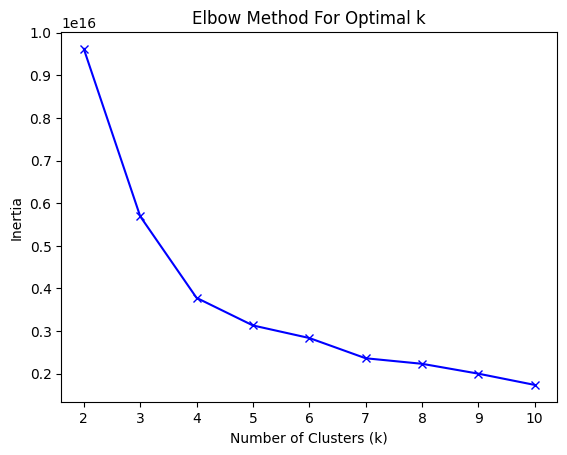

In [101]:
from sklearn.cluster import KMeans

inertia = []
K_range = range(2, 11)

for k in K_range:
    # Update pipeline with new k
    temp_model = Pipeline([
        ('scaler', RobustScaler()),
        ('model', KMeans(n_clusters=k, random_state=42))
    ])
    temp_model.fit(X_errors)
    inertia.append(temp_model.named_steps['model'].inertia_)

plt.plot(K_range, inertia, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()


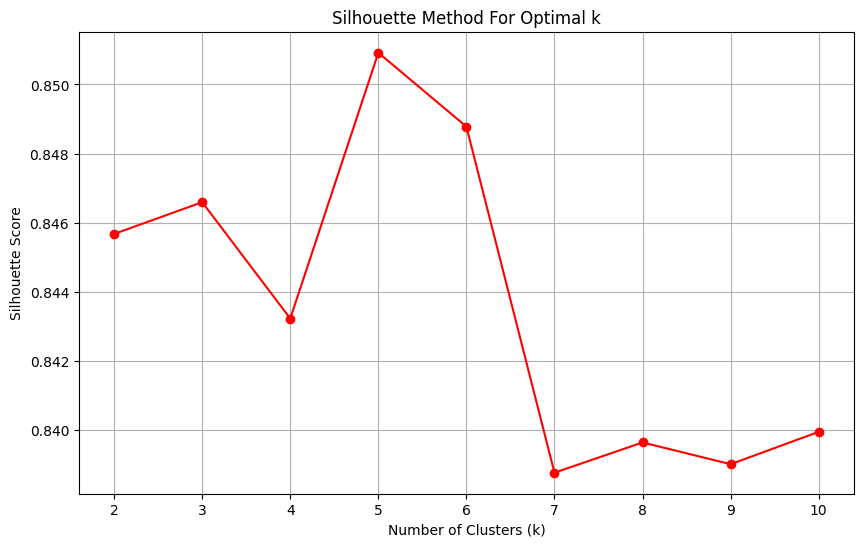

In [102]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# We use the scaled data since KMeans is distance-based
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_errors)

sil_scores = []
K_range = range(2, 11)

for k in K_range:
    # We need the labels to calculate the silhouette score
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)

# Plotting the results
plt.figure(figsize=(10, 6))
plt.plot(K_range, sil_scores, 'ro-') 
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Method For Optimal k')
plt.grid(True)
plt.show()

While the Elbow method suggests an optimal $k=4$, the Silhouette analysis shows a local improvement in cluster cohesion at $k=5$. In the context of payroll anomaly detection, $k=5$ provides a more granular segmentation of outliers without the significant loss of structure seen at higher values of $k$. This allows for better differentiation between 'extreme' financial anomalies and 'moderate' data entries."

In [103]:
from sklearn.cluster import KMeans
model_Kmeans = Pipeline([
        ('scaler', RobustScaler()),
        ('model', KMeans(n_clusters=5, random_state=66))
    ])

kmeans = model_Kmeans.fit(X_errors)

In [104]:
cluster_labels = kmeans.named_steps['model'].labels_

In [105]:
X_errors.columns

Index(['Anomaly_GB', 'Transport', 'Présence', 'Heures Supplementaire  65%',
       'Brut pour 13eme mois', 'Logement', 'Heures supplémentaires 60%',
       'Salaire horaire', 'Rappel Heures supplément.30%',
       'Rappel -Heures supplément.60%', 'Heures supplémentaires 30%',
       'Cherete de vie', 'Salaire de base', 'Heures Majorée 20%',
       'Rappel -Heures supplément.65%', 'Absence non justifié',
       'Indem Fin Contrat', 'Solde Congé', 'Primes', 'Regularisations',
       'Avances_Prets', 'Indem_Divers'],
      dtype='object')

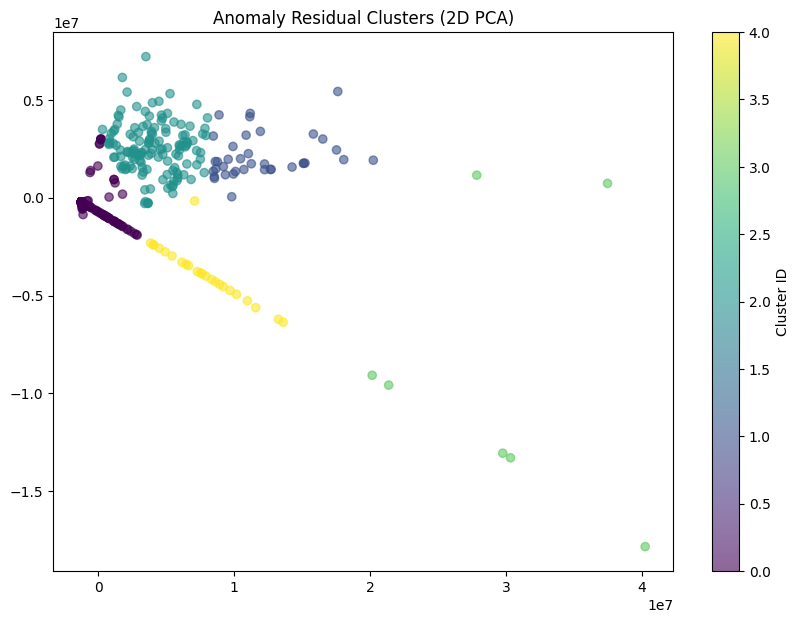

In [106]:
from sklearn.decomposition import PCA

# 1. Fit the model
cluster_labels = model_Kmeans.named_steps['model'].labels_
 
# 2. Get the SCALED data (using only the original features)
# We use the scaler already inside your pipeline 
X_scaled = model_Kmeans.named_steps['scaler'].transform(X_errors)

# 4. Now it's safe to add the Cluster column for other analysis
X_errors['Cluster'] = cluster_labels

# 5. Run PCA on the scaled original features
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 6. Plot using the PCA coordinates
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6)
plt.title('Anomaly Residual Clusters (2D PCA)')
plt.colorbar(scatter, label='Cluster ID')
plt.show()


In [107]:
# See which features define each group
cluster_summary = X_errors.groupby('Cluster').mean()
print(cluster_summary)


         Anomaly_GB  Transport  Présence  Heures Supplementaire  65%  \
Cluster                                                                
0              1.00 408,011.06    182.77                        2.44   
1              1.00 474,850.30    173.33                        1.41   
2              1.00 338,309.74    173.33                        1.46   
3              1.00 641,910.71    173.33                        0.00   
4              1.00 547,647.90    173.33                        1.04   

         Brut pour 13eme mois   Logement  Heures supplémentaires 60%  \
Cluster                                                                
0                  485,456.90 449,586.94                        9.07   
1                  435,471.05 366,028.51                        7.47   
2                  269,951.82 173,576.03                        6.69   
3                 -125,000.00 643,412.57                        0.00   
4                  110,397.92 534,577.93                       

In [108]:
# Create a dictionary to store your samples
samples = {}

for cluster_id in sorted(X_errors['Cluster'].unique()):
    # Pull 3 random examples from this cluster
    # Using .sample() ensures you don't just see the first few rows
    samples[f"Cluster_{cluster_id}"] = X_errors[X_errors['Cluster'] == cluster_id]

# Display one for inspection
import pandas as pd
all_samples = pd.concat(samples.values())
print(all_samples)

      Anomaly_GB    Transport  Présence  Heures Supplementaire  65%  \
5              1   550,000.00    173.33                        0.00   
6              1         0.00    240.00                        0.00   
7              1 1,000,000.00    173.33                        0.00   
9              1 1,100,000.00    173.33                        0.00   
16             1         0.00    240.00                        0.00   
...          ...          ...       ...                         ...   
1906           1   375,000.00    173.33                        0.00   
2171           1   496,820.00    173.33                        0.00   
2374           1   346,687.50    173.33                       11.00   
2500           1   353,777.00    173.33                        0.00   
2652           1   375,000.00    173.33                        0.00   

      Brut pour 13eme mois     Logement  Heures supplémentaires 60%  \
5              -125,000.00   550,000.00                        0.00   
6    

In [109]:
X_errors.columns

Index(['Anomaly_GB', 'Transport', 'Présence', 'Heures Supplementaire  65%',
       'Brut pour 13eme mois', 'Logement', 'Heures supplémentaires 60%',
       'Salaire horaire', 'Rappel Heures supplément.30%',
       'Rappel -Heures supplément.60%', 'Heures supplémentaires 30%',
       'Cherete de vie', 'Salaire de base', 'Heures Majorée 20%',
       'Rappel -Heures supplément.65%', 'Absence non justifié',
       'Indem Fin Contrat', 'Solde Congé', 'Primes', 'Regularisations',
       'Avances_Prets', 'Indem_Divers', 'Cluster'],
      dtype='object')

In [110]:
X_errors.to_csv("cluster_samples.csv", index=False)

In [111]:
X_errors.columns


Index(['Anomaly_GB', 'Transport', 'Présence', 'Heures Supplementaire  65%',
       'Brut pour 13eme mois', 'Logement', 'Heures supplémentaires 60%',
       'Salaire horaire', 'Rappel Heures supplément.30%',
       'Rappel -Heures supplément.60%', 'Heures supplémentaires 30%',
       'Cherete de vie', 'Salaire de base', 'Heures Majorée 20%',
       'Rappel -Heures supplément.65%', 'Absence non justifié',
       'Indem Fin Contrat', 'Solde Congé', 'Primes', 'Regularisations',
       'Avances_Prets', 'Indem_Divers', 'Cluster'],
      dtype='object')

In [112]:
X_errors_test=X_errors.drop(columns=['Cluster','Indem_Divers','Avances_Prets','Regularisations','Primes', 'Indem Fin Contrat', 'Solde Congé','Présence']) 

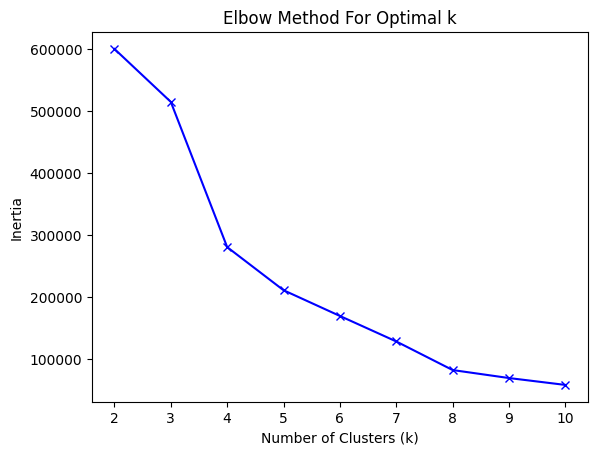

In [113]:
from sklearn.cluster import KMeans

inertia = []
K_range = range(2, 11)

for k in K_range:
    # Update pipeline with new k
    temp_model = Pipeline([
        ('scaler', RobustScaler()),
        ('model', KMeans(n_clusters=k, random_state=42))
    ])
    temp_model.fit(X_errors_test)
    inertia.append(temp_model.named_steps['model'].inertia_)

plt.plot(K_range, inertia, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()


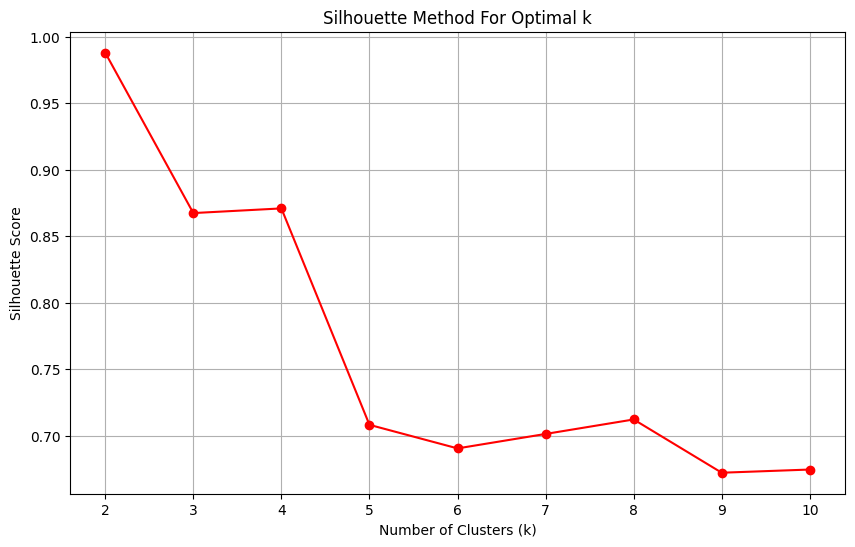

In [114]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# We use the scaled data since KMeans is distance-based
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_errors_test)

sil_scores = []
K_range = range(2, 11)

for k in K_range:
    # We need the labels to calculate the silhouette score
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)

# Plotting the results
plt.figure(figsize=(10, 6))
plt.plot(K_range, sil_scores, 'ro-') 
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Method For Optimal k')
plt.grid(True)
plt.show()

In [115]:
model_Kmeans_test = Pipeline([
        ('scaler', RobustScaler()),
        ('model', KMeans(n_clusters=4, random_state=42))
    ])

kmeans = model_Kmeans_test.fit(X_errors_test)

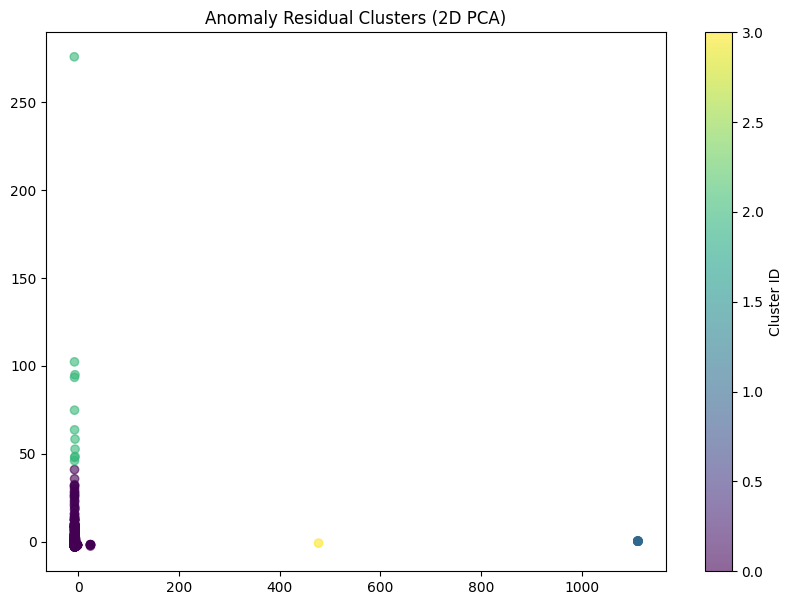

In [116]:
from sklearn.decomposition import PCA

# 1. Fit the model
cluster_labels = model_Kmeans_test.named_steps['model'].labels_
 
# 2. Get the SCALED data (using only the original features)
# We use the scaler already inside your pipeline 
X_scaled = model_Kmeans_test.named_steps['scaler'].transform(X_errors_test)

# 4. Now it's safe to add the Cluster column for other analysis
X_errors_test['Cluster'] = cluster_labels

# 5. Run PCA on the scaled original features
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 6. Plot using the PCA coordinates
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6)
plt.title('Anomaly Residual Clusters (2D PCA)')
plt.colorbar(scatter, label='Cluster ID')
plt.show()


In [117]:
clusters_residuals=X_errors
clusters_residuals_test=X_errors_test

In [118]:
clusters_residuals['csal_nosal'] = anomalies_residuals.loc[X_errors.index, 'csal_nosal']
clusters_residuals['DATE'] = anomalies_residuals.loc[X_errors.index, 'DATE']
clusters_residuals['Pred_GB'] = anomalies_residuals.loc[X_errors.index, 'Pred_GB']
clusters_residuals['Residual_GB'] = anomalies_residuals.loc[X_errors.index, 'Residual_GB']
clusters_residuals['Net à payer'] = anomalies_residuals.loc[X_errors.index, 'Net à payer_x']

In [119]:
clusters_residuals_test['csal_nosal'] = anomalies_residuals.loc[X_errors.index, 'csal_nosal']
clusters_residuals_test['DATE'] = anomalies_residuals.loc[X_errors.index, 'DATE']
clusters_residuals_test['Pred_GB'] = anomalies_residuals.loc[X_errors.index, 'Pred_GB']
clusters_residuals_test['Residual_GB'] = anomalies_residuals.loc[X_errors.index, 'Residual_GB']
clusters_residuals_test['Net à payer'] = anomalies_residuals.loc[X_errors.index, 'Net à payer_x']

In [120]:
X_errors_test.columns

Index(['Anomaly_GB', 'Transport', 'Heures Supplementaire  65%',
       'Brut pour 13eme mois', 'Logement', 'Heures supplémentaires 60%',
       'Salaire horaire', 'Rappel Heures supplément.30%',
       'Rappel -Heures supplément.60%', 'Heures supplémentaires 30%',
       'Cherete de vie', 'Salaire de base', 'Heures Majorée 20%',
       'Rappel -Heures supplément.65%', 'Absence non justifié', 'Cluster',
       'csal_nosal', 'DATE', 'Pred_GB', 'Residual_GB', 'Net à payer'],
      dtype='object')

In [121]:
clusters_residuals_test.to_csv("cluster_samples_test.csv", index=False)

In [122]:
clusters_residuals.to_csv("cluster_samples.csv", index=False)

## Réntrainement du modele et correction des problemes de performance du modèle et rédiction des faux positifs 

### Suppresssion des colonnes du bruit

In [123]:
X_res.columns

Index(['Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Heures supplémentaires 60%', 'Salaire horaire', 'Jours Travaillés',
       'Net à payer', 'Total congés acquis période',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Heures supplémentaires 30%', 'Cherete de vie', 'Salaire de base',
       'Heures Majorée 20%', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Indem Fin Contrat', 'Solde Congé', 'Primes',
       'Regularisations', 'Avances_Prets', 'Indem_Divers'],
      dtype='object')

In [124]:
X_res2=X_res[X_res['Jours Travaillés']==0]

### Séparer les cas de fin de contrat

In [125]:
X_res2=X_res[(X_res['Solde Congé']==0) & (X_res['Indem Fin Contrat']==0)]

In [126]:
end_of_contract=X_res[(X_res['Solde Congé']!=0) | (X_res['Indem Fin Contrat']!=0)]  
end_of_contract.shape

(421, 25)

In [127]:
end_of_contract.info()

<class 'pandas.core.frame.DataFrame'>
Index: 421 entries, 50 to 15614
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Valeur trentième               421 non-null    float64
 1   Transport                      421 non-null    float64
 2   Présence                       421 non-null    float64
 3   Heures Supplementaire  65%     421 non-null    float64
 4   Brut pour 13eme mois           421 non-null    float64
 5   Logement                       421 non-null    float64
 6   Heures supplémentaires 60%     421 non-null    float64
 7   Salaire horaire                421 non-null    float64
 8   Jours Travaillés               421 non-null    float64
 9   Net à payer                    421 non-null    float64
 10  Total congés acquis période    421 non-null    float64
 11  Rappel Heures supplément.30%   421 non-null    float64
 12  Rappel -Heures supplément.60%  421 non-null    float

In [128]:
X_res2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14598 entries, 0 to 15625
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Valeur trentième               14598 non-null  float64
 1   Transport                      14598 non-null  float64
 2   Présence                       14598 non-null  float64
 3   Heures Supplementaire  65%     14598 non-null  float64
 4   Brut pour 13eme mois           14598 non-null  float64
 5   Logement                       14598 non-null  float64
 6   Heures supplémentaires 60%     14598 non-null  float64
 7   Salaire horaire                14598 non-null  float64
 8   Jours Travaillés               14598 non-null  float64
 9   Net à payer                    14598 non-null  float64
 10  Total congés acquis période    14598 non-null  float64
 11  Rappel Heures supplément.30%   14598 non-null  float64
 12  Rappel -Heures supplément.60%  14598 non-null  floa

In [129]:
df_reduced_res.fillna(0,inplace=True)

In [130]:
df_mod=df_reduced_res[df_reduced_res['Jours Travaillés']==0].fillna(0)
df_mod=df_reduced_res[(df_reduced_res['Solde Congé']==0) & (df_reduced_res['Indem Fin Contrat']==0)].fillna(0)

In [131]:
df_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14598 entries, 0 to 15625
Data columns (total 27 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   csal_nosal                     14598 non-null  int64  
 1   DATE                           14598 non-null  object 
 2   Valeur trentième               14598 non-null  float64
 3   Transport                      14598 non-null  float64
 4   Présence                       14598 non-null  float64
 5   Heures Supplementaire  65%     14598 non-null  float64
 6   Brut pour 13eme mois           14598 non-null  float64
 7   Logement                       14598 non-null  float64
 8   Heures supplémentaires 60%     14598 non-null  float64
 9   Salaire horaire                14598 non-null  float64
 10  Jours Travaillés               14598 non-null  float64
 11  Net à payer                    14598 non-null  float64
 12  Total congés acquis période    14598 non-null  floa

### Revenir aux colonnes avant feature engineeing

In [132]:
cols_pre_FE = [
      "Divers Prêts", "Rappel Prime d'ancienneté",
    "Avance sur salaires Prestatair", "Prorata Renumeration precedent",
    "Frais Medicaux", "Jour Férié 100%", "Remboursement trop perçu",
    "Acompte sur Salaire", "Rappel Salaire en Plus" 
   
]

In [133]:
end_of_contract.columns

Index(['Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Heures supplémentaires 60%', 'Salaire horaire', 'Jours Travaillés',
       'Net à payer', 'Total congés acquis période',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Heures supplémentaires 30%', 'Cherete de vie', 'Salaire de base',
       'Heures Majorée 20%', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Indem Fin Contrat', 'Solde Congé', 'Primes',
       'Regularisations', 'Avances_Prets', 'Indem_Divers'],
      dtype='object')

In [134]:
X_res2=X_res2.drop(columns=['Avances_Prets','Indem_Divers','Regularisations','Jours Travaillés','Solde Congé','Indem Fin Contrat','Total congés acquis période'])

In [135]:
end_of_contract=end_of_contract.drop(columns=['Avances_Prets','Indem_Divers','Regularisations','Jours Travaillés','Total congés acquis période'])

In [136]:
end_of_contract=end_of_contract.join(df_reduced.loc[end_of_contract.index,cols_pre_FE])

In [137]:
end_of_contract['csal_nosal']=df_reduced.loc[end_of_contract.index,'csal_nosal']
end_of_contract['DATE']=df_reduced.loc[end_of_contract.index,'DATE']

In [138]:
end_of_contract.head()

,Valeur trentième,Transport,Présence,Heures Supplementaire 65%,Brut pour 13eme mois,Logement,Heures supplémentaires 60%,Salaire horaire,Net à payer,Rappel Heures supplément.30%,...,Rappel Prime d'ancienneté,Avance sur salaires Prestatair,Prorata Renumeration precedent,Frais Medicaux,Jour Férié 100%,Remboursement trop perçu,Acompte sur Salaire,Rappel Salaire en Plus,csal_nosal,DATE
50,1.00,"346,687.50",173.33,0.00,"-125,000.00","150,231.25",0.00,"15,834.59","11,378,269.00",0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,821,2025-10-31
100,20.00,"346,687.50",173.33,7.00,"429,887.00","150,231.25",8.00,"15,967.93","14,932,252.00",0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,187,2025-06-30
165,6.00,"322,500.00",173.33,0.00,"-125,000.00","139,750.00",0.00,"15,749.58","3,915,332.00",0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,224,2024-09-30
183,1.00,"346,687.50",173.33,0.00,"101,745.00","150,231.25",4.00,"15,967.93","13,298,515.00",0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80,2025-10-31
188,1.00,"346,687.50",173.33,0.00,"-125,000.00","150,231.25",0.00,"17,101.36","13,703,542.00",0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,92,2025-10-31


In [139]:
end_of_contract.to_csv("end_of_contract.csv",index=False)

In [140]:
X_res2=X_res2.join(df_reduced.loc[X_res2.index,cols_pre_FE])

In [141]:
X_res2.fillna(0,inplace=True)

In [142]:
X_res2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14598 entries, 0 to 15625
Data columns (total 27 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Valeur trentième                14598 non-null  float64
 1   Transport                       14598 non-null  float64
 2   Présence                        14598 non-null  float64
 3   Heures Supplementaire  65%      14598 non-null  float64
 4   Brut pour 13eme mois            14598 non-null  float64
 5   Logement                        14598 non-null  float64
 6   Heures supplémentaires 60%      14598 non-null  float64
 7   Salaire horaire                 14598 non-null  float64
 8   Net à payer                     14598 non-null  float64
 9   Rappel Heures supplément.30%    14598 non-null  float64
 10  Rappel -Heures supplément.60%   14598 non-null  float64
 11  Heures supplémentaires 30%      14598 non-null  float64
 12  Cherete de vie                  14598

In [143]:
X = X_res2.drop(columns=['Net à payer'])
y = X_res2['Net à payer']


In [144]:
X_res2.columns 

Index(['Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Heures supplémentaires 60%', 'Salaire horaire', 'Net à payer',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Heures supplémentaires 30%', 'Cherete de vie', 'Salaire de base',
       'Heures Majorée 20%', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Primes', 'Divers Prêts',
       'Rappel Prime d'ancienneté', 'Avance sur salaires Prestatair',
       'Prorata Renumeration precedent', 'Frais Medicaux', 'Jour Férié 100%',
       'Remboursement trop perçu', 'Acompte sur Salaire',
       'Rappel Salaire en Plus'],
      dtype='object')

In [145]:
X.columns

Index(['Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Heures supplémentaires 60%', 'Salaire horaire',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Heures supplémentaires 30%', 'Cherete de vie', 'Salaire de base',
       'Heures Majorée 20%', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Primes', 'Divers Prêts',
       'Rappel Prime d'ancienneté', 'Avance sur salaires Prestatair',
       'Prorata Renumeration precedent', 'Frais Medicaux', 'Jour Férié 100%',
       'Remboursement trop perçu', 'Acompte sur Salaire',
       'Rappel Salaire en Plus'],
      dtype='object')

In [146]:
X_sal=X.drop(columns=['Salaire horaire'])

In [149]:
X.shape

(14598, 26)

### Model testing

In [ ]:
cv_strategy = GroupKFold(n_splits=5)
models = {
    # Baseline — simple, interpretable
    'Ridge': Pipeline([
        ('scaler', RobustScaler()),
        ('model', ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42))
    ]),

    
    # Non-linear + robust via ensemble
    'Random Forest' : RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=20,
    max_features=0.8, 
    random_state=42 
),
    
    # Non-linear + captures complex patterns
    'Gradient Boosting' : GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=4,
    min_samples_leaf=20,
    subsample=0.8,
    random_state=42
),

'XGBoost' : XGBRegressor(
    n_estimators=400,
    learning_rate=0.03,
    max_depth=4,

    min_child_weight=3,
    gamma=0,

    subsample=0.8,
    colsample_bytree=0.8,

    reg_alpha=0,
    reg_lambda=2,

    random_state=42
),

'LightGBM' : LGBMRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=4,
    num_leaves=15,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1
),

'CatBoost' : CatBoostRegressor(
    iterations=500,
    learning_rate=0.03,
    depth=4,
    l2_leaf_reg=3,
    subsample=0.8,
    random_state=42,
    verbose=0
),

}



fig = plt.figure(figsize=(30, 10))
all_residuals = {}
for i,( name, model) in enumerate (models.items()):  
    mae_scores = []
    r2_scores = []
    mae_scores_train = []
    r2_scores_train = []
    mape_scores = []
    med_ae_scores = []
    mape_scores_train = []
    med_ae_scores_train = []

    y_pred = cross_val_predict(model, X, y,cv=cv_strategy, groups=df_mod['csal_nosal'],n_jobs=-1)
    residuals = y - y_pred 
    rel_residuals= residuals / y
    median=np.median(rel_residuals)
    MAD=np.median(np.abs(rel_residuals-median))
    robust_z_score= 0.6745 * (rel_residuals - median) / MAD    
    
    all_residuals[name] = {  
        'y_pred'    : y_pred,
        'residuals' : residuals,
        'z_scores'  : robust_z_score,
        'rel_residuals': rel_residuals
    }
    
    print(f"\n{name}")
    print(f"  R²           : {r2_score(y, y_pred):.4f}")
    print(f"  MAE          : {mean_absolute_error(y, y_pred):,.0f} FCFA")
    print(f"Test MAPE : {mean_absolute_percentage_error(y, y_pred)*100:.2f} %")
    print(f"Test MedAE : {median_absolute_error(y, y_pred):,.0f} FCFA")
    print(f"  Anomalies    : {(robust_z_score.abs() > 4.25).sum()}")
    for fold, (train_idx, test_idx) in enumerate(
        cv_strategy.split(X, y, groups=df_mod['csal_nosal']),
        start=1
    ):

        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_train, y_train)

        pred_fold = model.predict(X_test)
        pred_train = model.predict(X_train)

        mae_scores.append(
            mean_absolute_error(y_test, pred_fold)
        )

        r2_scores.append(
            r2_score(y_test, pred_fold)
        )

        mae_scores_train.append(
            mean_absolute_error(y_train, pred_train)
        )

        r2_scores_train.append(
            r2_score(y_train, pred_train)
        )

        mape_scores.append(
            mean_absolute_percentage_error(y_test, pred_fold)
        )
        med_ae_scores.append(
            median_absolute_error(y_test, pred_fold)
        )

        mape_scores_train.append(
            mean_absolute_percentage_error(y_train, pred_train)
        )
        med_ae_scores_train.append(
            median_absolute_error(y_train, pred_train)
        )

        print(f"Fold {fold}")
        print(f" Test MAE : {mean_absolute_error(y_test, pred_fold):,.0f}") 
        print(f" Test R²  : {r2_score(y_test, pred_fold):.4f}")
        print(f" Train MAE: {mean_absolute_error(y_train, pred_train):,.0f}")
        print(f" Train R² : {r2_score(y_train, pred_train):.4f}")
        print(f"Train MAPE : {mean_absolute_percentage_error(y_train, pred_train)*100:.2f} %")
        print(f"Train MedAE : {median_absolute_error(y_train, pred_train):,.0f} FCFA")
        print(f"Test MAPE : {mean_absolute_percentage_error(y_test, y_pred)*100:.2f} %")
        print(f"Test MedAE : {median_absolute_error(y_test, y_pred):,.0f} FCFA")
        print("-"*30)

    avg_mae = np.mean(mae_scores)
    avg_r2 = np.mean(r2_scores)
    avg_mae_train = np.mean(mae_scores_train)
    avg_r2_train = np.mean(r2_scores_train)
    

    print("\nAverage across folds")
    print(f" Test MAE : {np.mean(mae_scores):,.0f}")
    print(f" Test R²  : {np.mean(r2_scores):.4f}")
    print(f" Test MAPE : {np.mean(mape_scores)*100:.2f} %")
    print(f" Test MedAE : {np.mean(med_ae_scores):,.0f} FCFA")
    print(f" Train MAE: {np.mean(mae_scores_train):,.0f}")
    print(f" Train R² : {np.mean(r2_scores_train):.4f}")
    print(f" Train MAPE : {np.mean(mape_scores_train)*100:.2f} %")
    print(f" Train MedAE : {np.mean(med_ae_scores_train):,.0f} FCFA")

    print(f" Performance train vs test:")
    
    avg_r2_gap = np.mean(r2_scores_train) - np.mean(r2_scores)
    print(f"R² gap = {avg_r2_gap:.4f}")
    avg_mae_gap = np.mean(mae_scores_train) - np.mean(mae_scores)
    print(f"MAE gap = {avg_mae_gap:,.0f}")

    
    print("-" * 30)

    
    fig.add_subplot(3, 3, i+1)
    plt.scatter(y_pred, residuals)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel('Fitted Values')
    plt.ylabel('Residuals')
    plt.title(f'Residuals vs Fitted Plot - {name}')

plt.tight_layout()
plt.show()     



Ridge
  R²           : -104.5627
  MAE          : 4,153,277 FCFA
Test MAPE : 34.43 %
Test MedAE : 477,363 FCFA
  Anomalies    : 918
Fold 1
 Test MAE : 15,239,903
 Test R²  : -546.1965
 Train MAE: 1,437,356
 Train R² : 0.5426
Train MAPE : 29.15 %
Train MedAE : 492,655 FCFA


ValueError: Found input variables with inconsistent numbers of samples: [2920, 14598]

<Figure size 3000x1000 with 0 Axes>

## Hyperparameter tuning (GradientBoosting)

optuna.logging.set_verbosity(optuna.logging.INFO)

def objective(trial, X, y, groups):
    params = {
        'n_estimators' : trial.suggest_int('n_estimators', 250 ,500),
        # 2. CAPACITY CONTROL: Lower tree depths prevent memorization of sparse flags
        'max_depth': trial.suggest_int('max_depth', 2, 4), 
        # 3. SPARSITY DEFENSE: Force larger leaf sizes so rare categories don't isolate data points
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 15, 80),
        # 4. STOCHASTIC REGULARIZATION: Subsample rows and columns to prevent over-reliance on outliers
        'subsample': trial.suggest_float('subsample', 0.5, 0.8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.08),
        'random_state': 42 
    } 
    cv_strategy = GroupKFold(n_splits=5)
    cv_mae_scores = []
    cv_r2_scores = []
    cv_mae_train = []
    cv_r2_train = []
    
    for fold, (train_idx, val_idx) in enumerate(cv_strategy.split(X, y, groups=groups), start=1):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        model = GradientBoostingRegressor(**params)
        # model = HistGradientBoostingRegressor(**params, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20)
        model.fit(X_train, y_train)
        
        preds_train = model.predict(X_train)
        preds = model.predict(X_val)
        
        cv_mae_scores.append(mean_absolute_error(y_val, preds))
        cv_r2_scores.append(r2_score(y_val, preds))
        cv_mae_train.append(mean_absolute_error(y_train, preds_train))
        cv_r2_train.append(r2_score(y_train, preds_train))
        
    avg_mae = np.mean(cv_mae_scores)
    avg_r2 = np.mean(cv_r2_scores)
    avg_r2_train = np.mean(cv_r2_train)
    avg_mae_train = np.mean(cv_mae_train)
    
    trial.set_user_attr("cv_r2", avg_r2)
    trial.set_user_attr("cv_r2_train", avg_r2_train)
    trial.set_user_attr("cv_mae_train", avg_mae_train)
    
    return float(avg_mae)

        
# --- 2. Run Optuna Study ---
groups_array = df_mod['csal_nosal']

study = optuna.create_study(direction="minimize")
study.optimize(lambda trial: objective(trial, X, y, groups_array), n_trials=35,n_jobs=-1)

print("\n--- Optimization Complete via Cross-Validation ---")
print(f"Best CV MAE: {study.best_trial.value:.2f} FCFA")
print(f"Best CV MAE (Train): {study.best_trial.user_attrs['cv_mae_train']:.2f} FCFA")
print(f"Best CV R²: {study.best_trial.user_attrs['cv_r2']:.4f}")
print(f"Best CV R² (Train): {study.best_trial.user_attrs['cv_r2_train']:.4f}")
print("Best Hyperparameters:")
for k, v in study.best_trial.params.items():
    print(f"  * {k}: {v}")   


In [ ]:
optuna.logging.set_verbosity(optuna.logging.INFO)

def objective(trial, X, y, groups):
    params = {
        'n_estimators' : trial.suggest_int('n_estimators', 250 ,500),
        'max_depth': trial.suggest_int('max_depth', 2, 4), 
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 20, 80),
        'subsample': trial.suggest_float('subsample', 0.5, 0.8),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.08),
        'random_state': 42 
    } 
    cv_strategy = GroupKFold(n_splits=5)
    
    cv_mape_scores, cv_medae_scores, cv_mae_scores, cv_r2_scores = [], [], [], []
    cv_mape_train, cv_medae_train, cv_mae_train, cv_r2_train = [], [], [], []
    
    for train_idx, val_idx in cv_strategy.split(X, y, groups=groups):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        model = GradientBoostingRegressor(**params)
        model.fit(X_train, y_train)
        
        preds_train = model.predict(X_train)
        preds = model.predict(X_val)
        
        cv_mape_scores.append(mean_absolute_percentage_error(y_val, preds))
        cv_medae_scores.append(median_absolute_error(y_val, preds))
        cv_mae_scores.append(mean_absolute_error(y_val, preds))
        cv_r2_scores.append(r2_score(y_val, preds))
        
        cv_mape_train.append(mean_absolute_percentage_error(y_train, preds_train))
        cv_medae_train.append(median_absolute_error(y_train, preds_train))
        cv_mae_train.append(mean_absolute_error(y_train, preds_train))
        cv_r2_train.append(r2_score(y_train, preds_train))

    avg_mape = np.mean(cv_mape_scores)
    avg_medae = np.mean(cv_medae_scores)
    avg_mae = np.mean(cv_mae_scores)
    avg_r2 = np.mean(cv_r2_scores)
    
    avg_mape_train = np.mean(cv_mape_train)
    avg_medae_train = np.mean(cv_medae_train)
    avg_mae_train = np.mean(cv_mae_train)
    avg_r2_train = np.mean(cv_r2_train)

    trial.set_user_attr("cv_medae", avg_medae)
    trial.set_user_attr("cv_mae", avg_mae)
    trial.set_user_attr("cv_r2", avg_r2)
    
    trial.set_user_attr("cv_medae_train", avg_medae_train)
    trial.set_user_attr("cv_mae_train", avg_mae_train)
    trial.set_user_attr("cv_mape_train", avg_mape_train)
    trial.set_user_attr("cv_r2_train", avg_r2_train)

    return float(avg_mape)

groups_array = df_mod['csal_nosal']

study = optuna.create_study(direction="minimize")
study.optimize(lambda trial: objective(trial, X, y, groups_array), n_trials=45, n_jobs=-1)

print("\n--- Optimization Complete via Robust Cross-Validation ---")

best_mape_value = study.best_trial.value if study.best_trial.value is not None else 0.0

print(f"Best CV MAPE (Validation): {best_mape_value * 100:.2f}%")
print(f"Best CV MAPE (Train): {study.best_trial.user_attrs['cv_mape_train'] * 100:.2f}%")
print(f"Best CV MedAE (Validation): {study.best_trial.user_attrs['cv_medae']:.2f} FCFA")
print(f"Best CV MedAE (Train): {study.best_trial.user_attrs['cv_medae_train']:.2f} FCFA")
print(f"Best CV MAE (Train): {study.best_trial.user_attrs['cv_mae_train']:.2f} FCFA")
print(f"Best CV R² (Train): {study.best_trial.user_attrs['cv_r2_train']:.4f}")
print(f"Best CV MAE (Validation): {study.best_trial.user_attrs['cv_mae']:.2f} FCFA")
print(f"Best CV R² (Validation): {study.best_trial.user_attrs['cv_r2']:.4f}")

print("\nBest Hyperparameters:")
for k, v in study.best_trial.params.items():
    print(f"  * {k}: {v}")   


[I 2026-07-05 20:25:03,627] A new study created in memory with name: no-name-ff32fec4-602b-4e86-b13b-f6e57fe72ef0
[I 2026-07-05 20:26:52,593] Trial 5 finished with value: 0.05318178650855844 and parameters: {'n_estimators': 356, 'max_depth': 3, 'min_samples_leaf': 27, 'subsample': 0.5212483716631948, 'learning_rate': 0.04477609951786969}. Best is trial 5 with value: 0.05318178650855844.
[I 2026-07-05 20:26:58,703] Trial 6 finished with value: 0.07596511351369784 and parameters: {'n_estimators': 482, 'max_depth': 2, 'min_samples_leaf': 72, 'subsample': 0.5654146129683867, 'learning_rate': 0.07247409937463861}. Best is trial 5 with value: 0.05318178650855844.
[I 2026-07-05 20:27:41,627] Trial 2 finished with value: 0.06397456184237932 and parameters: {'n_estimators': 393, 'max_depth': 3, 'min_samples_leaf': 77, 'subsample': 0.680149273902869, 'learning_rate': 0.06033977955971405}. Best is trial 5 with value: 0.05318178650855844.
[I 2026-07-05 20:28:12,429] Trial 1 finished with value: 0.


--- Optimization Complete via Robust Cross-Validation ---
Best CV MAPE (Validation): 5.02%
Best CV MAPE (Train): 3.52%
Best CV MedAE (Validation): 84558.73 FCFA
Best CV MedAE (Train): 78160.98 FCFA
Best CV MAE (Train): 184982.08 FCFA
Best CV R² (Train): 0.9910
Best CV MAE (Validation): 301977.90 FCFA
Best CV R² (Validation): 0.9648

Best Hyperparameters:
  * n_estimators: 398
  * max_depth: 3
  * min_samples_leaf: 39
  * subsample: 0.7590479884996688
  * learning_rate: 0.07912335866577824


In [ ]:
df_marsh=pd.read_csv("data marsh 2026.csv")

In [ ]:
df_marsh.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 372 entries, 0 to 371
Data columns (total 28 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   csal_nosal                      372 non-null    int64  
 1   DATE                            372 non-null    object 
 2   Salaire de base                 372 non-null    float64
 3   Transport                       344 non-null    float64
 4   Logement                        347 non-null    float64
 5   Cherete de vie                  352 non-null    float64
 6   Heures Supplementaire  65%      104 non-null    float64
 7   Heures supplémentaires 30%      145 non-null    float64
 8   Solde Congé                     2 non-null      float64
 9   Heures supplémentaires 60%      139 non-null    float64
 10  Primes                          372 non-null    int64  
 11  Absence non justifié            38 non-null     float64
 12  Acompte sur Salaire             372 

# Test Optuna's parameters using your manual evaluation script
gb_model = GradientBoostingRegressor(
    n_estimators=494,
    learning_rate=0.07215940690474996,
    max_depth=4, 
    min_samples_leaf=43,
    subsample=0.751277227504024,
    random_state=42
)

cv_strategy = GroupKFold(n_splits=5)
pred = cross_val_predict(gb_model, X, y, cv=cv_strategy, groups=df_mod['csal_nosal'], n_jobs=-1)
model = gb_model.fit(X, y)
pred_train = model.predict(X)
print("--- VERIFICATION ---")
print(f"R² (train): {r2_score(y, pred_train):.4f} ")
print (f" MAE (train): {mean_absolute_error(y, pred_train):,.0f} FCFA")
print(f"R² (test) : {r2_score(y, pred):.4f}")
print(f" MAE (test) : {mean_absolute_error(y, pred):,.0f} FCFA")
print(f"MAPE (train) : {mean_absolute_percentage_error(y, pred_train)*100:.2f} %")
print(f"MedAE (train) : {median_absolute_error(y, pred_train):,.0f} FCFA")
print(f"MAPE (test) : {mean_absolute_percentage_error(y, pred)*100:.2f} %")
print(f"MedAE (test) : {median_absolute_error(y, pred):,.0f} FCFA")

In [148]:
# Test Optuna's parameters using your manual evaluation script
gb_model = GradientBoostingRegressor(
    n_estimators=446,
    learning_rate=0.07215940690474996,
    max_depth=3, 
    min_samples_leaf=29,
    subsample=0.751277227504024,
    random_state=42
)

cv_strategy = GroupKFold(n_splits=5)
pred = cross_val_predict(gb_model, X, y, cv=cv_strategy, groups=df_mod['csal_nosal'], n_jobs=-1)
model = gb_model.fit(X, y)
pred_train = model.predict(X)
print("--- VERIFICATION ---")
print(f"R² (train): {r2_score(y, pred_train):.4f} ")
print (f" MAE (train): {mean_absolute_error(y, pred_train):,.0f} FCFA")
print(f"R² (test) : {r2_score(y, pred):.4f}")
print(f" MAE (test) : {mean_absolute_error(y, pred):,.0f} FCFA")
print(f"MAPE (train) : {mean_absolute_percentage_error(y, pred_train)*100:.2f} %")
print(f"MedAE (train) : {median_absolute_error(y, pred_train):,.0f} FCFA")
print(f"MAPE (test) : {mean_absolute_percentage_error(y, pred)*100:.2f} %")
print(f"MedAE (test) : {median_absolute_error(y, pred):,.0f} FCFA")

--- VERIFICATION ---
R² (train): 0.9935 
 MAE (train): 159,823 FCFA
R² (test) : 0.9637
 MAE (test) : 284,622 FCFA
MAPE (train) : 3.15 %
MedAE (train) : 71,502 FCFA
MAPE (test) : 5.00 %
MedAE (test) : 80,701 FCFA


# Test Optuna's parameters using your manual evaluation script
gb_model = GradientBoostingRegressor(
    n_estimators=554,
    learning_rate=0.05363025544040574,
    max_depth=3,
    min_samples_leaf=15,
    subsample=0.79872015473178,
    random_state=42
)

cv_strategy = GroupKFold(n_splits=5)
pred = cross_val_predict(gb_model, X, y, cv=cv_strategy, groups=df_mod['csal_nosal'], n_jobs=-1)
model = gb_model.fit(X, y)
pred_train = model.predict(X)
print("--- VERIFICATION ---")
print(f"R² (train): {r2_score(y, pred_train):.4f} ")
print (f" MAE (train): {mean_absolute_error(y, pred_train):,.0f} FCFA")
print(f"Old Manual Model R² : 0.9774  |  Old Manual MAE : 252,479 FCFA") 
print(f"New Optuna Model R² : {r2_score(y, pred):.4f}")
print(f"New Optuna Model MAE: {mean_absolute_error(y, pred):,.0f} FCFA")

In [ ]:
residuals=y - pred
rel_residuals= residuals / y

In [ ]:
for fold, (train_idx, test_idx) in enumerate(
        cv_strategy.split(X, y, groups=df_mod['csal_nosal']),
        start=1
        ):
        
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # Train
        gb_model.fit(X_train, y_train)

        # Predict
        pred_fold = gb_model.predict(X_test)

        # Metrics
        mae = mean_absolute_error(y_test, pred_fold)
        r2 = r2_score(y_test, pred_fold)

        print(f"Fold {fold}")
        print(f"  MAE : {mae:,.2f}")
        print(f"  R²  : {r2:.4f}")
        print("-" * 30)

Fold 1
  MAE : 341,369.19
  R²  : 0.9689
------------------------------
Fold 2
  MAE : 328,404.28
  R²  : 0.9627
------------------------------
Fold 3
  MAE : 238,457.96
  R²  : 0.9351
------------------------------
Fold 4
  MAE : 205,113.55
  R²  : 0.9872
------------------------------
Fold 5
  MAE : 309,746.95
  R²  : 0.9606
------------------------------


In [ ]:
print(f"mean of relative residuals: {np.mean(rel_residuals)*100:.4f}%")
print(f"median of relative residuals: {np.median(rel_residuals)*100:.4f}%")

mean of relative residuals: -1.5716%
median of relative residuals: -0.4236%


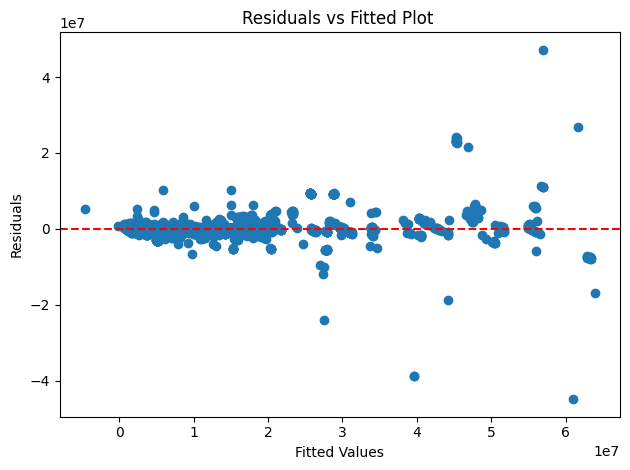

In [ ]:
plt.scatter(pred, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title(f'Residuals vs Fitted Plot ')
plt.tight_layout()
plt.show()  

In [ ]:
X_null=X.replace(0,np.nan)

In [ ]:
X_null.isnull().mean().mul(100).sort_values(ascending=False)

Divers Prêts                     99.94
Prorata Renumeration precedent   99.90
Jour Férié 100%                  99.86
Frais Medicaux                   99.86
Acompte sur Salaire              99.70
Rappel -Heures supplément.65%    99.66
Remboursement trop perçu         99.66
Avance sur salaires Prestatair   99.61
Rappel Prime d'ancienneté        99.61
Rappel -Heures supplément.60%    99.23
Rappel Heures supplément.30%     99.21
Heures Majorée 20%               99.14
Rappel Salaire en Plus           98.97
Absence non justifié             87.44
Heures Supplementaire  65%       67.50
Heures supplémentaires 60%       33.14
Heures supplémentaires 30%       32.40
Primes                           27.52
Transport                         7.44
Logement                          6.73
Brut pour 13eme mois              6.56
Cherete de vie                    6.49
Salaire horaire                   0.59
Salaire de base                   0.59
Présence                          0.03
Valeur trentième         

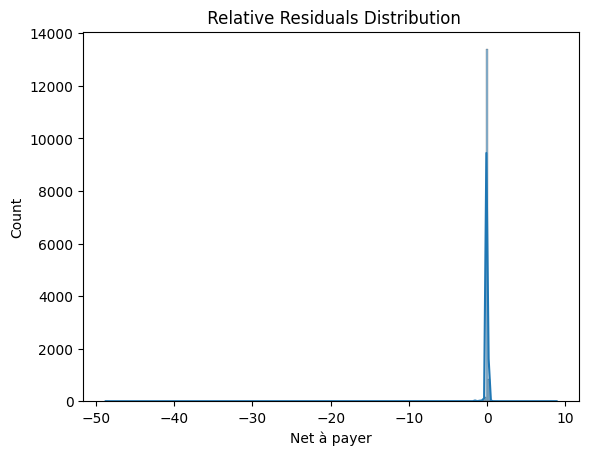

In [ ]:
# 2. Plot Histogram and KDE
sns.histplot(rel_residuals, kde=True)
plt.title(" Relative Residuals Distribution")
plt.show()

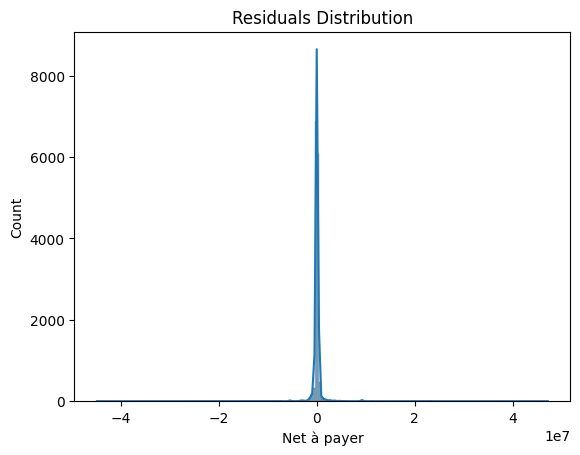

In [ ]:
# 2. Plot Histogram and KDE
sns.histplot(residuals, kde=True)
plt.title("Residuals Distribution")
plt.show()

In [ ]:
median=np.median(rel_residuals)
MAD=np.median(np.abs(rel_residuals-median))
robust_z_score= 0.6745 * (rel_residuals - median) / MAD    

In [ ]:
df_reduced_res.fillna(0,inplace=True)

In [ ]:
predictions=pd.DataFrame({
    'csal_nosal' : df_mod['csal_nosal'].values,
    'DATE'       : df_mod['DATE'].values,
    'Pred'    : pred, 
    'Residual' : residuals,
    'Relative Residual' : rel_residuals,
    'Anomaly' : (robust_z_score.abs() > 4.25).astype(int),
})

In [ ]:
predictions['Anomaly'].value_counts()

Anomaly
0    13902
1      696
Name: count, dtype: int64

In [ ]:
X_res2['csal_nosal'] = df_mod.loc[X_res2.index, 'csal_nosal']
X_res2['DATE'] = df_mod.loc[X_res2.index, 'DATE']

In [ ]:
anomalies_residuals=predictions.merge(X_res2,on=['csal_nosal','DATE'],how ='inner') 

In [ ]:
anomalies_residuals.columns

Index(['csal_nosal', 'DATE', 'Pred', 'Residual', 'Relative Residual',
       'Anomaly', 'Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Heures supplémentaires 60%', 'Salaire horaire', 'Net à payer',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Heures supplémentaires 30%', 'Cherete de vie', 'Salaire de base',
       'Heures Majorée 20%', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Primes', 'Divers Prêts',
       'Rappel Prime d'ancienneté', 'Avance sur salaires Prestatair',
       'Prorata Renumeration precedent', 'Frais Medicaux', 'Jour Férié 100%',
       'Remboursement trop perçu', 'Acompte sur Salaire',
       'Rappel Salaire en Plus'],
      dtype='object')

In [ ]:
X_res2.sort_values(by='Net à payer', ascending=False).head(20)

,Valeur trentième,Transport,Présence,Heures Supplementaire 65%,Brut pour 13eme mois,Logement,Heures supplémentaires 60%,Salaire horaire,Net à payer,Rappel Heures supplément.30%,...,Rappel Prime d'ancienneté,Avance sur salaires Prestatair,Prorata Renumeration precedent,Frais Medicaux,Jour Férié 100%,Remboursement trop perçu,Acompte sur Salaire,Rappel Salaire en Plus,csal_nosal,DATE
14943,22.00,0.00,240.00,0.00,0.00,0.00,0.00,33.33,"104,196,511.00",0.00,...,0.00,0.00,"4,267.00",0.00,0.00,0.00,0.00,0.00,578,2023-10-31
12895,14.00,0.00,173.33,0.00,0.00,0.00,0.00,37.50,"88,452,936.00",0.00,...,0.00,0.00,"3,900.00",0.00,0.00,0.00,0.00,0.00,743,2024-02-29
2273,22.00,0.00,173.33,0.00,0.00,0.00,0.00,46.15,"69,561,440.00",0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,755,2025-12-31
4258,19.00,0.00,173.33,0.00,0.00,0.00,0.00,46.15,"69,372,240.00",0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,755,2025-11-30
12026,23.00,0.00,173.33,0.00,0.00,0.00,0.00,46.15,"69,258,240.00",0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,755,2025-10-31
7724,21.00,0.00,173.33,0.00,0.00,0.00,0.00,46.15,"68,748,240.00",0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,755,2024-09-30
15386,21.00,0.00,173.33,0.00,0.00,0.00,0.00,46.15,"68,476,880.00",0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,755,2024-08-31
8970,21.00,0.00,173.33,0.00,0.00,0.00,0.00,46.15,"68,431,840.00",0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,755,2024-03-31
13338,19.00,0.00,173.33,0.00,0.00,0.00,0.00,46.15,"68,417,120.00",0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,755,2024-11-30
3636,23.00,0.00,173.33,0.00,0.00,0.00,0.00,46.15,"68,359,760.00",0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,755,2024-07-31


In [ ]:
anomalies_residuals.sort_values(by='Residual', ascending=False).head(20)

,csal_nosal,DATE,Pred,Residual,Relative Residual,Anomaly,Valeur trentième,Transport,Présence,Heures Supplementaire 65%,...,Primes,Divers Prêts,Rappel Prime d'ancienneté,Avance sur salaires Prestatair,Prorata Renumeration precedent,Frais Medicaux,Jour Férié 100%,Remboursement trop perçu,Acompte sur Salaire,Rappel Salaire en Plus
13955,578,2023-10-31,"57,015,854.50","47,180,656.50",0.45,1,22.00,0.00,240.00,0.00,...,0.00,0.00,0.00,0.00,"4,267.00",0.00,0.00,0.00,0.00,0.00
12048,743,2024-02-29,"61,701,424.12","26,751,511.88",0.30,1,14.00,0.00,173.33,0.00,...,0.00,0.00,0.00,0.00,"3,900.00",0.00,0.00,0.00,0.00,0.00
2120,755,2025-12-31,"45,284,041.66","24,277,398.34",0.35,1,22.00,0.00,173.33,0.00,...,"400,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
11240,755,2025-10-31,"45,280,233.51","23,978,006.49",0.35,1,23.00,0.00,173.33,0.00,...,"400,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3981,755,2025-11-30,"45,408,915.20","23,963,324.80",0.35,1,19.00,0.00,173.33,0.00,...,"400,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
7209,755,2024-09-30,"45,297,999.75","23,450,240.25",0.34,1,21.00,0.00,173.33,0.00,...,"400,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
14371,755,2024-08-31,"45,297,999.75","23,178,880.25",0.34,1,21.00,0.00,173.33,0.00,...,"400,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3393,755,2024-07-31,"45,280,233.51","23,079,526.49",0.34,1,23.00,0.00,173.33,0.00,...,"400,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
5463,755,2024-10-31,"45,280,233.51","23,010,006.49",0.34,1,23.00,0.00,173.33,0.00,...,"400,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
12463,755,2024-11-30,"45,408,915.20","23,008,204.80",0.34,1,19.00,0.00,173.33,0.00,...,"400,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [ ]:
anomalies_residuals.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14598 entries, 0 to 14597
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   csal_nosal                      14598 non-null  int64  
 1   DATE                            14598 non-null  object 
 2   Pred                            14598 non-null  float64
 3   Residual                        14598 non-null  float64
 4   Relative Residual               14598 non-null  float64
 5   Anomaly                         14598 non-null  int64  
 6   Valeur trentième                14598 non-null  float64
 7   Transport                       14598 non-null  float64
 8   Présence                        14598 non-null  float64
 9   Heures Supplementaire  65%      14598 non-null  float64
 10  Brut pour 13eme mois            14598 non-null  float64
 11  Logement                        14598 non-null  float64
 12  Heures supplémentaires 60%      

In [ ]:
explainer_gb = shap.TreeExplainer(gb_model)
shap_values_gb = explainer_gb(X)

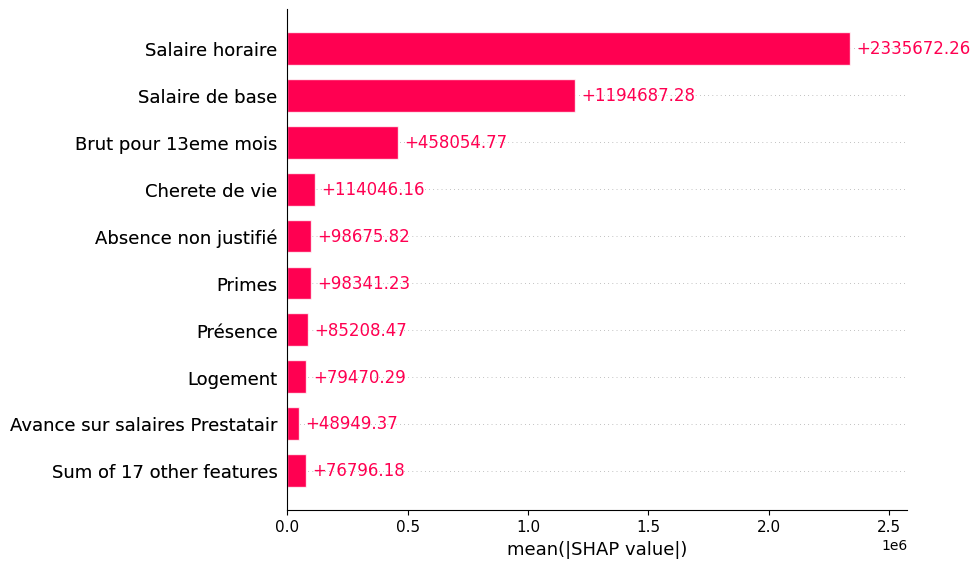

In [ ]:
shap.plots.bar(shap_values_gb) 

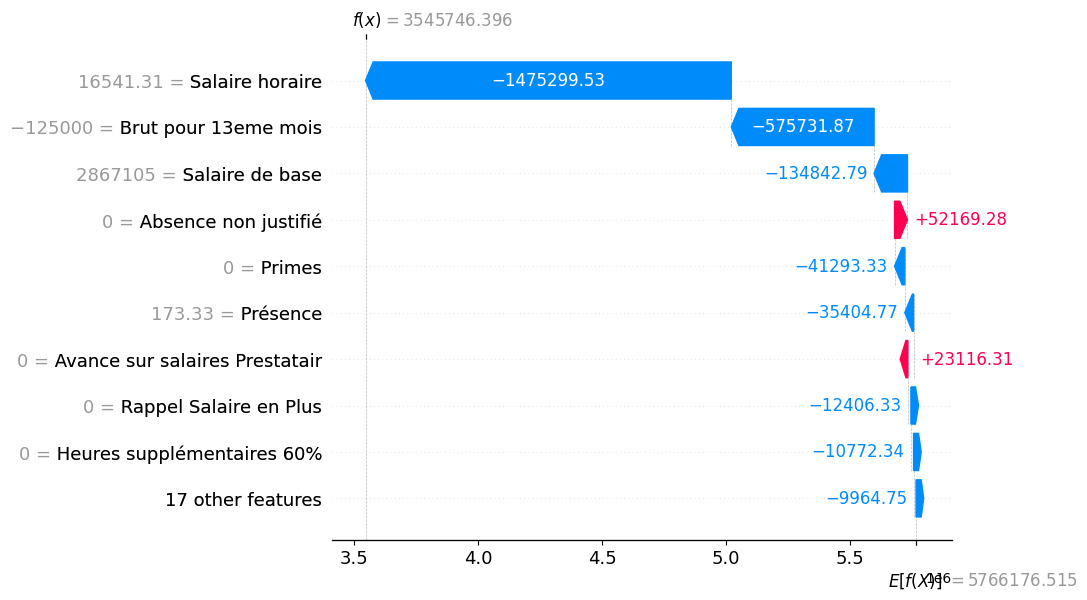

In [ ]:
shap.plots.waterfall(shap_values_gb[0])

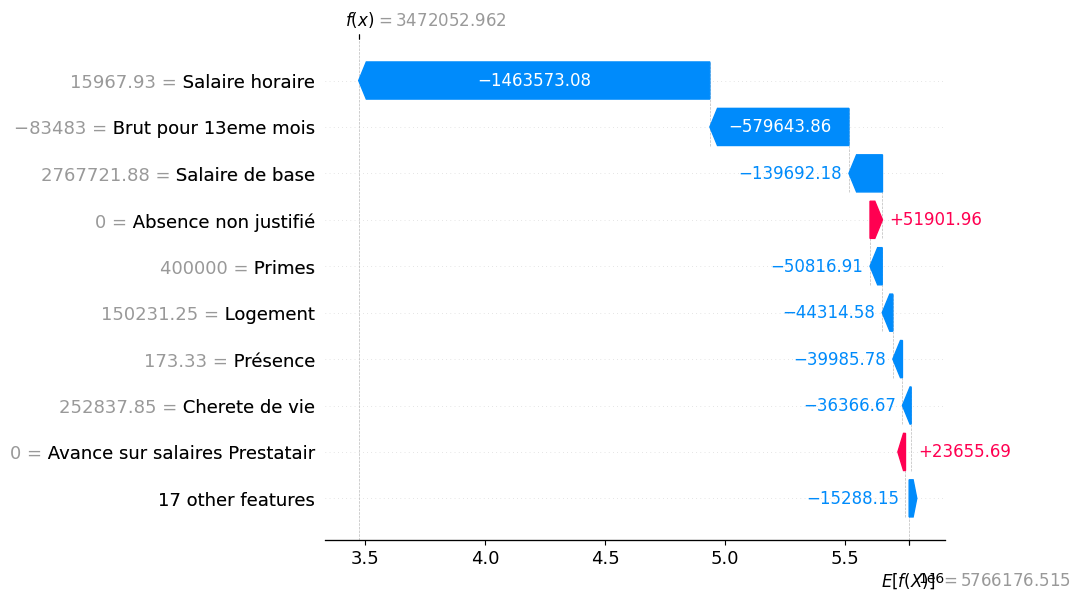

In [ ]:
shap.plots.waterfall(shap_values_gb[2])

In [ ]:
# Get importances
importances = gb_model.feature_importances_
# Map to feature names
feature_importance_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
print(feature_importance_df.sort_values(by='Importance', ascending=False))


                           Feature  Importance
7                  Salaire horaire        0.49
12                 Salaire de base        0.48
4             Brut pour 13eme mois        0.01
2                         Présence        0.00
11                  Cherete de vie        0.00
19  Avance sur salaires Prestatair        0.00
15            Absence non justifié        0.00
5                         Logement        0.00
16                          Primes        0.00
25          Rappel Salaire en Plus        0.00
1                        Transport        0.00
0                 Valeur trentième        0.00
6       Heures supplémentaires 60%        0.00
24             Acompte sur Salaire        0.00
18       Rappel Prime d'ancienneté        0.00
8     Rappel Heures supplément.30%        0.00
23        Remboursement trop perçu        0.00
3       Heures Supplementaire  65%        0.00
9    Rappel -Heures supplément.60%        0.00
10      Heures supplémentaires 30%        0.00
14   Rappel -

In [ ]:
anomalies_residuals.columns

Index(['csal_nosal', 'DATE', 'Pred', 'Residual', 'Relative Residual',
       'Anomaly', 'Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Heures supplémentaires 60%', 'Salaire horaire', 'Net à payer',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Heures supplémentaires 30%', 'Cherete de vie', 'Salaire de base',
       'Heures Majorée 20%', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Primes', 'Divers Prêts',
       'Rappel Prime d'ancienneté', 'Avance sur salaires Prestatair',
       'Prorata Renumeration precedent', 'Frais Medicaux', 'Jour Férié 100%',
       'Remboursement trop perçu', 'Acompte sur Salaire',
       'Rappel Salaire en Plus'],
      dtype='object')

In [ ]:
anomalies_res=anomalies_residuals[anomalies_residuals['Anomaly']==1]

In [ ]:
anomalies_res.to_csv("anomalies_by_residual.csv", index=False)

In [ ]:
# Combien d'anomalies par employé ?
anomalies_per_employee = anomalies_res.groupby('csal_nosal').size().sort_values(ascending=False)
print(anomalies_per_employee.shape)
print(anomalies_per_employee.head(20)) 


(254,)
csal_nosal
573    27
587    24
264    23
762    22
784    19
171    18
636    18
41     17
208    16
585    14
755    12
743    12
479    12
269    10
478     9
485     9
279     9
586     9
786     9
65      8
dtype: int64


In [ ]:
# Combien d'anomalies par mois ?
anomalies_per_month = anomalies_res.groupby('DATE').size().sort_values(ascending=False)
print(anomalies_per_month) 

DATE
2024-03-31    70
2023-10-31    54
2023-11-30    45
2024-08-31    43
2023-09-30    33
2024-02-29    32
2024-11-30    31
2025-01-31    26
2024-07-31    25
2024-09-30    23
2025-02-28    23
2024-06-30    23
2024-01-31    22
2024-10-31    21
2024-04-30    21
2023-12-31    21
2025-03-31    20
2024-05-31    18
2025-05-31    15
2024-12-31    15
2025-04-30    15
2025-07-31    15
2025-08-31    14
2025-12-31    13
2025-06-30    13
2023-08-31    12
2025-09-30    11
2025-10-31    11
2025-11-30    11
dtype: int64


## Isolation Forrest 


 Isolation Forest works by:
 Randomly selecting a feature    
 Randomly selecting a split value    
 Building many random trees (called an isolation tree)     
 Measuring how easy it is to isolate a data point     
 Points that are very different from the rest — whether very high or low — tend to get isolated in fewer splits → marked as anomalies.


In [ ]:
X_IF=anomalies_residuals.drop(columns=['csal_nosal','DATE','Pred','Residual','Anomaly','Salaire de base','Net à payer'])

In [ ]:
X_IF.columns

Index(['Relative Residual', 'Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Heures supplémentaires 60%', 'Salaire horaire',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Heures supplémentaires 30%', 'Cherete de vie', 'Heures Majorée 20%',
       'Rappel -Heures supplément.65%', 'Absence non justifié', 'Primes',
       'Divers Prêts', 'Rappel Prime d'ancienneté',
       'Avance sur salaires Prestatair', 'Prorata Renumeration precedent',
       'Frais Medicaux', 'Jour Férié 100%', 'Remboursement trop perçu',
       'Acompte sur Salaire', 'Rappel Salaire en Plus'],
      dtype='object')

In [ ]:
# Seuil minimum de lignes non-nulles pour considérer une corrélation valide

MIN_VALID_ROWS = 200 # à ajuster selon ton contexte
numeric_df = X_IF.select_dtypes(include='number')
# Calculer la corrélation seulement si assez de valeurs communes
corr_matrix = numeric_df.corr(min_periods=MIN_VALID_ROWS).abs()

# Garder seulement le triangle supérieur
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Trouver les paires avec corrélation > 0.99
redundant_pairs = []
for col in upper_triangle.columns:
    for idx in upper_triangle.index:
        val = upper_triangle.loc[idx, col]
        if pd.isna(val) or not isinstance(val, (int, float)):
            continue
        if val > 0.7:
            # Double vérification : compter les lignes non-nulles communes
            common_non_null = numeric_df[[idx, col]].dropna().shape[0]
            if common_non_null < MIN_VALID_ROWS:
                continue  # ignorer cette paire
            redundant_pairs.append({
                'colonne_1': idx,
                'colonne_2': col,
                'correlation': round(val, 4),
                'lignes_comparées': common_non_null 
            })

df_redundant = pd.DataFrame(redundant_pairs).sort_values('correlation', ascending=False)
print(df_redundant)

                      colonne_1                      colonne_2  correlation  \
2  Rappel Heures supplément.30%  Rappel -Heures supplément.60%         0.83   
1          Brut pour 13eme mois     Heures supplémentaires 60%         0.82   
0                     Transport                       Logement         0.70   

   lignes_comparées  
2             14598  
1             14598  
0             14598  


In [ ]:
from sklearn.ensemble import IsolationForest

model_if=IsolationForest(n_estimators=500, random_state=42)
model_if.fit(X_IF) 


,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",500
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary ` for more details.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",42
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary `... versionadded:: 0.21",False


In [ ]:
anomalies_residuals["anomaly_scores"]=model_if.decision_function(X_IF)
anomalies_residuals["Anomaly_IF"]=model_if.predict(X_IF)
print(anomalies_residuals["Anomaly_IF"].value_counts())

Anomaly_IF
 1    14209
-1      389
Name: count, dtype: int64


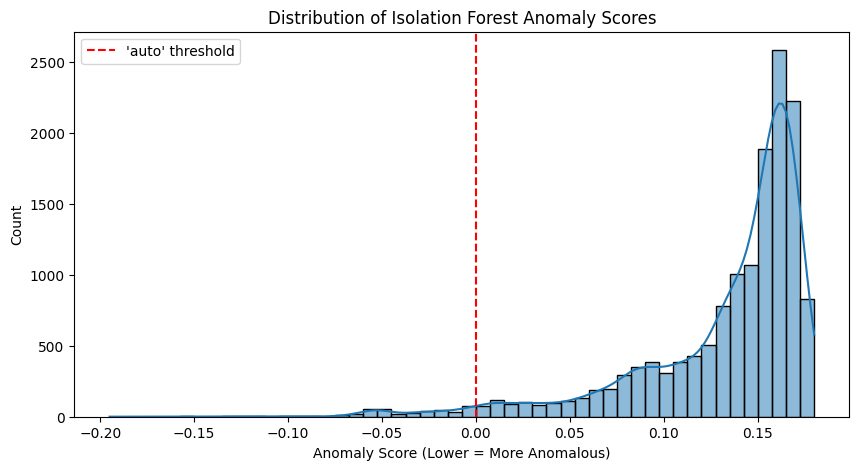

In [ ]:
# 1. Get the raw anomaly scores (lower means more anomalous)
scores = model_if.decision_function(X_IF)



plt.figure(figsize=(10, 5))
sns.histplot(scores, bins=50, kde=True)
plt.axvline(x=0, color='red', linestyle='--', label="'auto' threshold")
plt.title("Distribution of Isolation Forest Anomaly Scores")
plt.xlabel("Anomaly Score (Lower = More Anomalous)")
plt.ylabel("Count")
plt.legend()
plt.show()


In [ ]:
anomalies_IF=anomalies_residuals[anomalies_residuals['Anomaly_IF']==-1]

In [ ]:
anomalies_IF.drop(columns=['Pred','Residual','Relative Residual','Anomaly'],inplace=True)

C:\Users\abdou\AppData\Local\Temp\ipykernel_36960\1584756027.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  anomalies_IF.drop(columns=['Pred','Residual','Relative Residual','Anomaly'],inplace=True)


In [ ]:
anomalies_by_residual=anomalies_residuals[anomalies_residuals['Anomaly']==1]
anomalies_by_residual.shape 

(696, 35)

In [ ]:
anomalies_by_residual.drop(columns=['Anomaly_IF','anomaly_scores'],inplace=True)

C:\Users\abdou\AppData\Local\Temp\ipykernel_36960\3404577047.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  anomalies_by_residual.drop(columns=['Anomaly_IF','anomaly_scores'],inplace=True)


## Chargement des fichiers csv

In [ ]:
anomalies_by_residual.to_csv("anomalies_by_residual.csv", index=False)

In [ ]:
anomalies_IF.to_csv("anomalies_by_IF.csv", index=False)

In [ ]:
both=anomalies_residuals[(anomalies_residuals['Anomaly'] == 1) & (anomalies_residuals['Anomaly_IF'] == -1)]

In [ ]:
both.shape 

(181, 35)

In [ ]:
both.to_csv("anomalies_both.csv", index=False)

In [ ]:
anomalies_residuals.to_csv("anomalies.csv", index=False)

In [ ]:
end_of_contract.to_csv("end_of_contract.csv",index=False)

In [ ]:
# Combien d'anomalies par employé ?
anomalies_per_employee = anomalies_IF.groupby('csal_nosal').size().sort_values(ascending=False)
print(anomalies_per_employee.shape)
print(anomalies_per_employee.head(20)) 


(140,)
csal_nosal
171    29
746    23
762    22
784    19
98     16
778    16
208    16
479    15
751    12
3      12
777    10
795     8
361     8
655     7
476     6
104     5
783     5
749     5
285     5
449     4
dtype: int64


In [ ]:
# Combien d'anomalies par mois ?
anomalies_per_month = anomalies_IF.groupby('DATE').size().sort_values(ascending=False)
print(anomalies_per_month) 

DATE
2023-10-31    35
2024-06-30    27
2024-08-31    20
2025-07-31    20
2025-01-31    18
2025-02-28    17
2025-04-30    16
2024-10-31    15
2024-11-30    15
2025-05-31    15
2024-12-31    14
2024-07-31    14
2025-06-30    14
2023-09-30    13
2025-03-31    13
2025-08-31    13
2025-10-31    12
2025-11-30    12
2025-09-30    11
2025-12-31    11
2024-04-30    10
2024-09-30    10
2024-01-31     9
2023-12-31     9
2023-11-30     6
2024-05-31     6
2024-03-31     5
2024-02-29     5
2023-08-31     4
dtype: int64


In [ ]:
# Trier par score d'anomalie (plus négatif = plus anormal)
df_anomalies_sorted = anomalies_residuals.sort_values('anomaly_scores', ascending=True)

# Top 20 cas les plus anormaux
top_anomalies = df_anomalies_sorted.head(20)

print("\nTop 20 anomalies les plus marquées :")
for _, row in top_anomalies.iterrows():
    print(f"\nEmployé {row['csal_nosal']} — {row['DATE']}")
    print(f"  Net à payer    : {row['Net à payer']:,.0f} FCFA")
    print(f"  Anomaly score  : {row['anomaly_scores']:.4f}")
    print("-" * 80)


Top 20 anomalies les plus marquées :

Employé 259 — 2024-02-29
  Net à payer    : 25,361,511 FCFA
  Anomaly score  : -0.1950
--------------------------------------------------------------------------------

Employé 749 — 2024-12-31
  Net à payer    : 9,464,900 FCFA
  Anomaly score  : -0.1654
--------------------------------------------------------------------------------

Employé 361 — 2023-08-31
  Net à payer    : 3,013,076 FCFA
  Anomaly score  : -0.1572
--------------------------------------------------------------------------------

Employé 749 — 2025-03-31
  Net à payer    : 9,585,504 FCFA
  Anomaly score  : -0.1500
--------------------------------------------------------------------------------

Employé 259 — 2023-11-30
  Net à payer    : 18,522,543 FCFA
  Anomaly score  : -0.1467
--------------------------------------------------------------------------------

Employé 477 — 2024-06-30
  Net à payer    : 6,213,396 FCFA
  Anomaly score  : -0.1373
---------------------------------

## TreeSHAP ( interprets the model based on the average path length)

In [ ]:
explainer = shap.TreeExplainer(model_if)
tree_shap_values = explainer(X_IF)

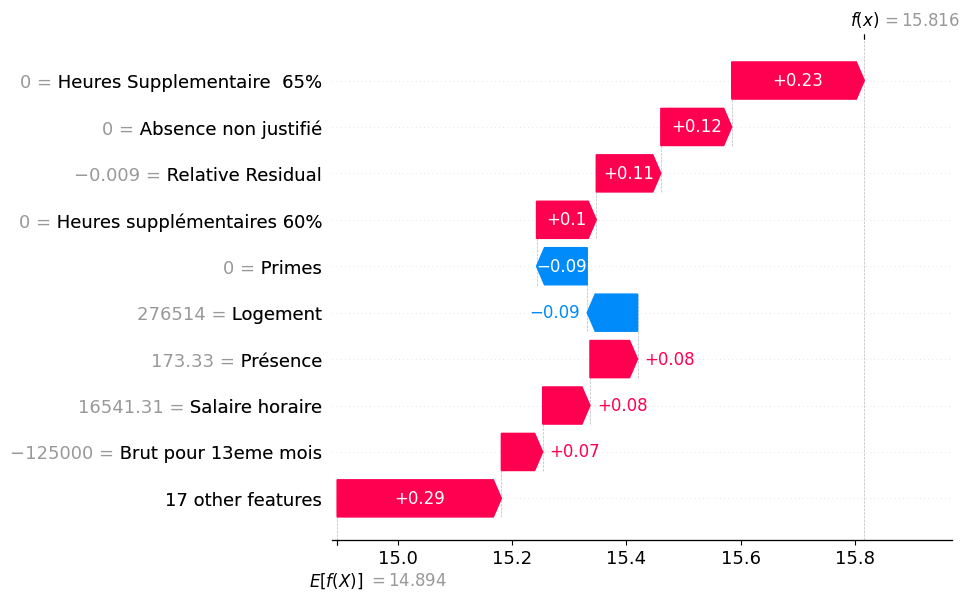

In [ ]:
shap.plots.waterfall(tree_shap_values[0])

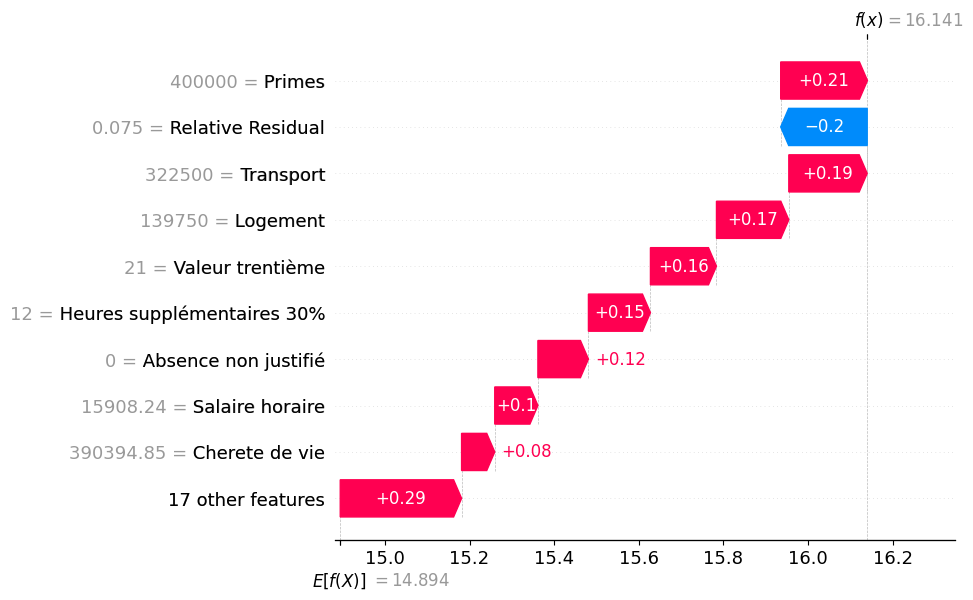

In [ ]:
shap.plots.waterfall(tree_shap_values[338]) 

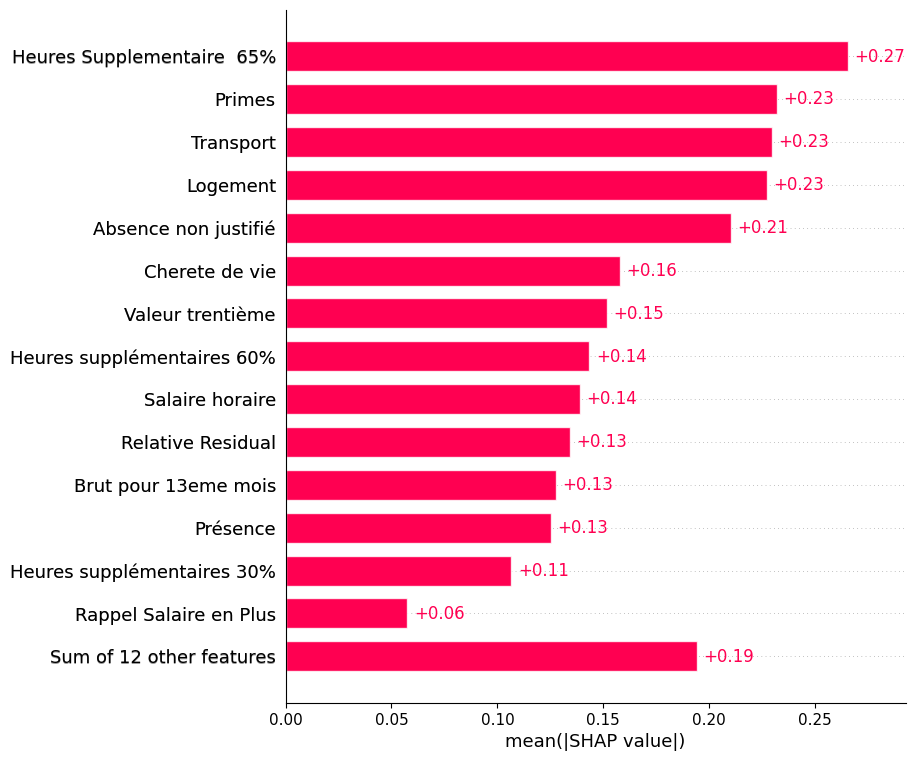

In [ ]:
shap.plots.bar(tree_shap_values, max_display=15)

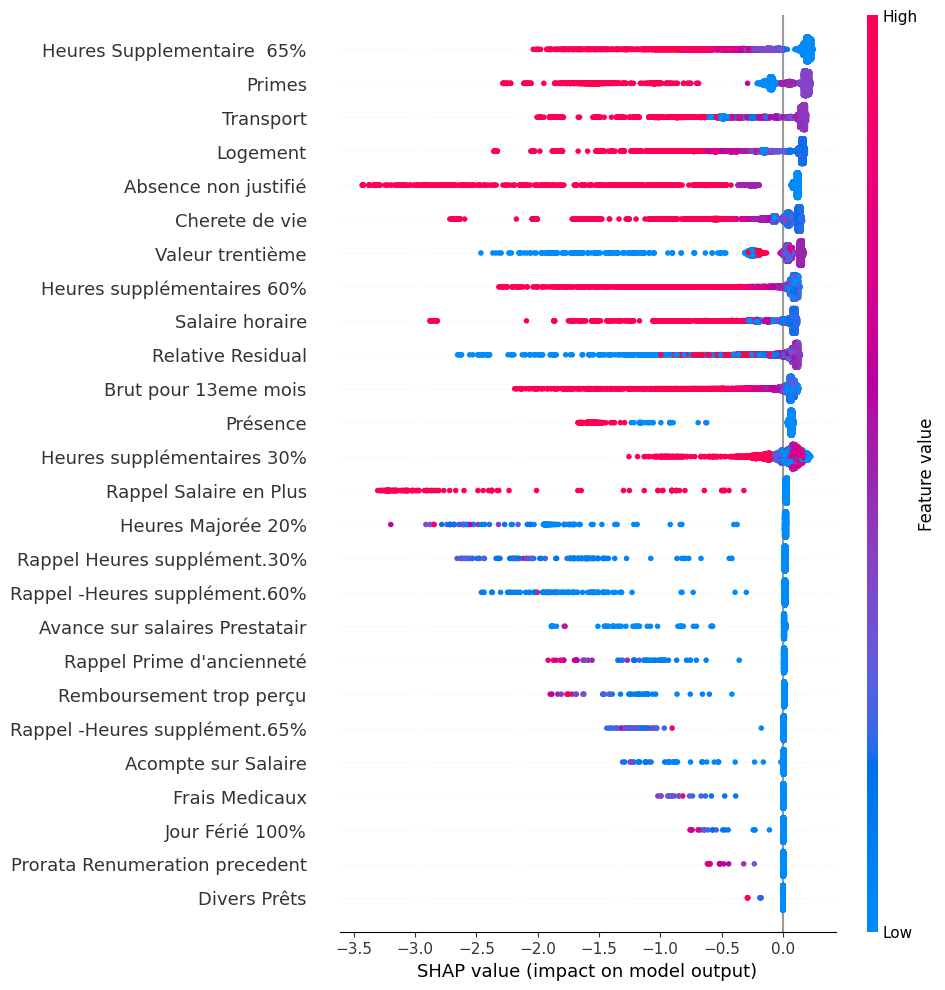

In [ ]:
shap.plots.beeswarm(tree_shap_values,max_display=27)

In [ ]:
anomalies_residuals.to_csv("anomalies.csv", index=False)

 ### Model to predict residuals for shap interprebality in anomalies flagged by residuals (Error Model)

In [ ]:
anomalies_residuals.columns

Index(['csal_nosal', 'DATE', 'Pred', 'Residual', 'Relative Residual',
       'Anomaly', 'Valeur trentième', 'Transport', 'Présence',
       'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement',
       'Heures supplémentaires 60%', 'Salaire horaire', 'Net à payer',
       'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%',
       'Heures supplémentaires 30%', 'Cherete de vie', 'Salaire de base',
       'Heures Majorée 20%', 'Rappel -Heures supplément.65%',
       'Absence non justifié', 'Primes', 'Divers Prêts',
       'Rappel Prime d'ancienneté', 'Avance sur salaires Prestatair',
       'Prorata Renumeration precedent', 'Frais Medicaux', 'Jour Férié 100%',
       'Remboursement trop perçu', 'Acompte sur Salaire',
       'Rappel Salaire en Plus', 'anomaly_scores', 'Anomaly_IF'],
      dtype='object')

In [ ]:
X_er=X
y_er=anomalies_residuals['Anomaly']

In [ ]:
train_X, test_X, train_y, test_y = train_test_split(X_er, y_er, test_size=0.2,stratify=y_er, random_state=42)

What happens if you use Signed Relative Residuals?If you use signed residuals, your errors can be positive (the model guessed too high) or negative (the model guessed too low).If you feed these signed numbers into your error model:They cancel each other out: If the model over-predicts by 20% on one row and under-predicts by 20% on an identical row, the average error appears to be 0%. The error model will think there is no problem at all.The meaning of "high" changes: A tree model splits data to find where the target is highest. If your target is signed, a high number means "massive over-prediction," while a low (negative) number means "massive under-prediction." Your SHAP charts will become highly confusing because a negative SHAP value could mean either a great prediction (close to zero) or a massive under-prediction

In [ ]:
y_er

0        0
1        0
2        0
3        0
4        0
        ..
14593    0
14594    0
14595    0
14596    0
14597    0
Name: Anomaly, Length: 14598, dtype: int64

In [ ]:
# 1. Dynamically calculate the scale_pos_weight for class balancing
num_neg = np.sum(y_er == 0)
num_pos = np.sum(y_er == 1)
scale_weight_val = num_neg / num_pos

# 2. Define the regularized XGBoost model
error_model_xgb = XGBClassifier(
    max_depth=4,                  # Keeps depth restricted for clean SHAP interpretations
    n_estimators=200,             # Matches your RF architecture
    learning_rate=0.05,           # Small steps prevent overfitting during boosting
    scale_pos_weight=scale_weight_val, # Replaces class_weight="balanced"
    random_state=42,
    n_jobs=-1,
)

# 3. Use your robust CV strategy (using the exact same parameters)
cv_strategy = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# 4. Get predicted PROBABILITIES for validation
pred_proba_xgb = cross_val_predict(
    error_model_xgb,
    X_er,
    y_er,
    cv=cv_strategy,
    groups=df_mod["csal_nosal"],
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

# 5. Get hard 0/1 predictions for validation metrics
pred_labels_xgb = cross_val_predict(
    error_model_xgb,
    X_er,
    y_er,
    cv=cv_strategy,
    groups=df_mod["csal_nosal"],
    n_jobs=-1,
)

# 6. Fit on the whole dataset to get training performance
model_xgb = error_model_xgb.fit(X_er, y_er)
pred_train_proba_xgb = error_model_xgb.predict_proba(X_er)[:, 1]
pred_train_labels_xgb = error_model_xgb.predict(X_er)

# 7. Print comparative results
print("--- XGBOOST VERIFICATION ---")
print(f"AUC_ROC (train): {roc_auc_score(y_er, pred_train_proba_xgb):.4f} | F1 (train): {f1_score(y_er, pred_train_labels_xgb):.4f}")
print(f"AUC_ROC (val)  : {roc_auc_score(y_er, pred_proba_xgb):.4f} | F1 (val)  : {f1_score(y_er, pred_labels_xgb):.4f}")
print("Precision:", precision_score(y_er, pred_labels_xgb))
print("Recall:", recall_score(y_er, pred_labels_xgb))
print("PR-AUC (Average Precision):", average_precision_score(y_er, pred_labels_xgb))

--- XGBOOST VERIFICATION ---
AUC_ROC (train): 0.9737 | F1 (train): 0.5569
AUC_ROC (val)  : 0.8875 | F1 (val)  : 0.3803
Precision: 0.27411167512690354
Recall: 0.6206896551724138
PR-AUC (Average Precision): 0.18822295024600838


In [ ]:


# 1. Dynamically calculate scale_pos_weight for class balancing
num_neg = np.sum(y_er == 0)
num_pos = np.sum(y_er == 1)
scale_weight_val = num_neg / num_pos

# 2. Define the regularized LightGBM model
# We set max_depth and num_leaves to keep it regularized and SHAP-friendly
error_model_lgb = LGBMClassifier(
    max_depth=4,                  # Restrict depth for clean SHAP interpretations
    num_leaves=15,                # Must be < 2^max_depth (2^4 = 16)
    n_estimators=200,             # Matches your previous architectures
    learning_rate=0.05,           # Small steps prevent overfitting
    scale_pos_weight=scale_weight_val, # Replaces class_weight="balanced"
    random_state=42,
    n_jobs=-1,
    verbosity=-1                  # Silences unnecessary warning logs
)

# 3. Robust CV strategy (identical parameters to lock in a fair comparison)
cv_strategy = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# 4. Get predicted PROBABILITIES for validation
pred_proba_lgb = cross_val_predict(
    error_model_lgb,
    X_er,
    y_er,
    cv=cv_strategy,
    groups=df_mod["csal_nosal"],
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

# 5. Get hard 0/1 predictions for validation metrics
pred_labels_lgb = cross_val_predict(
    error_model_lgb,
    X_er,
    y_er,
    cv=cv_strategy,
    groups=df_mod["csal_nosal"],
    n_jobs=-1,
)

# 6. Fit on the whole dataset to get training performance
model_lgb = error_model_lgb.fit(X_er, y_er)
pred_train_proba_lgb = error_model_lgb.predict_proba(X_er)[:, 1]
pred_train_labels_lgb = error_model_lgb.predict(X_er)

# 7. Print comparative results
print("--- LIGHTGBM VERIFICATION ---")
print(f"AUC_ROC (train): {roc_auc_score(y_er, pred_train_proba_lgb):.4f} | F1 (train): {f1_score(y_er, pred_train_labels_lgb):.4f}")
print(f"AUC_ROC (val)  : {roc_auc_score(y_er, pred_proba_lgb):.4f} | F1 (val)  : {f1_score(y_er, pred_labels_lgb):.4f}")
print("Precision:", precision_score(y_er, pred_labels_lgb))
print("Recall:", recall_score(y_er, pred_labels_lgb))
print("PR-AUC (Average Precision):", average_precision_score(y_er, pred_labels_lgb))

--- LIGHTGBM VERIFICATION ---
AUC_ROC (train): 0.9732 | F1 (train): 0.5280
AUC_ROC (val)  : 0.8917 | F1 (val)  : 0.4217
Precision: 0.3034700315457413
Recall: 0.6910919540229885
PR-AUC (Average Precision): 0.22445374202602703


In [ ]:
error_model_rf = RandomForestClassifier( 
    max_depth=4,
    n_estimators=200,
    class_weight="balanced", # Crucial because anomalies are rare
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)

# 2. Correct CV strategy that handles BOTH stratification (0/1) AND grouping (Employee ID)
cv_strategy = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Get predicted PROBABILITIES for validation AUC-ROC
pred_proba_rf = cross_val_predict(
    error_model_rf,
    X_er,
    y_er,
    cv=cv_strategy,
    groups=df_mod["csal_nosal"],
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

# 4. Get hard 0/1 predictions for validation F1-score
pred_labels_rf = cross_val_predict(
    error_model_rf,
    X_er,
    y_er,
    cv=cv_strategy,
    groups=df_mod["csal_nosal"],
    n_jobs=-1,
)

# 5. Fit on the whole dataset to get training performance
model_rf = error_model_rf.fit(X_er, y_er)
pred_train_proba_rf = error_model_rf.predict_proba(X_er)[:, 1]
pred_train_labels_rf = error_model_rf.predict(X_er)

print("--- RANDOM FORREST VERIFICATION ---")
print(
    f"AUC_ROC (train): {roc_auc_score(y_er, pred_train_proba_rf):.4f} | F1 (train): {f1_score(y_er, pred_train_labels_rf):.4f}"
)
print(
    f"AUC_ROC (val)  : {roc_auc_score(y_er, pred_proba_rf):.4f} | F1 (val)  : {f1_score(y_er, pred_labels_rf):.4f}"
)

print("Precision:", precision_score(y_er, pred_labels_rf))
print("Recall:", recall_score(y_er, pred_labels_rf))
print(f"PR-AUC (Average Precision):",average_precision_score(y_er, pred_labels_rf))


--- RANDOM FORREST VERIFICATION ---
AUC_ROC (train): 0.9251 | F1 (train): 0.3157
AUC_ROC (val)  : 0.8794 | F1 (val)  : 0.2996
Precision: 0.18441127694859039
Recall: 0.7988505747126436
PR-AUC (Average Precision): 0.15690740941700312


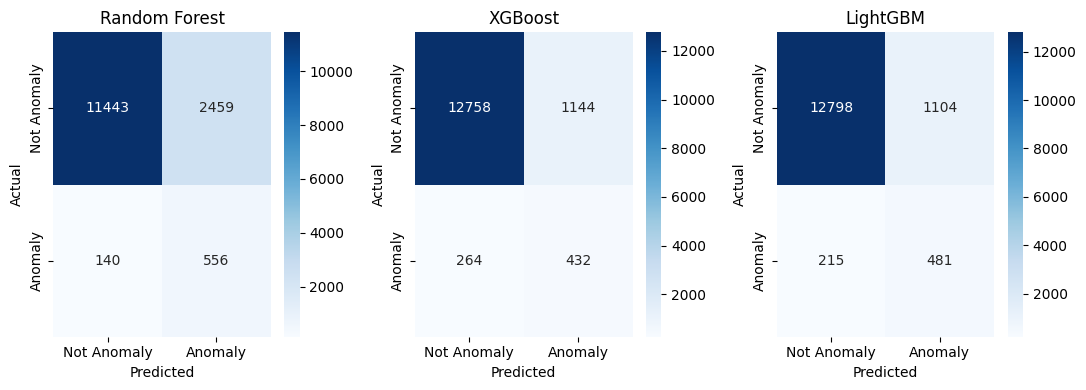

In [ ]:

cm_rf = confusion_matrix(y_er, pred_labels_rf)
cm_xgb = confusion_matrix(y_er, pred_labels_xgb)
cm_lgbm = confusion_matrix(y_er, pred_labels_lgb)

# Création de la figure avec 4 sous-plots
fig, axes = plt.subplots(1, 3, figsize=(11, 4))

models_cm = [
    (cm_rf, "Random Forest"),
    (cm_xgb, "XGBoost"),
    (cm_lgbm, "LightGBM")
]

# Boucle pour afficher chaque matrice
for ax, (cm, title) in zip(axes.flatten(), models_cm):
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Not Anomaly', 'Anomaly'],
        yticklabels=['Not Anomaly', 'Anomaly'],
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


While LightGBM exhibited marginal improvements in validation Precision and PR-AUC ($0.2120$ vs. $0.1531$), Random Forest was chosen as the final diagnostic engine due to its superior Recall ($74.06\%$ capturing 591 active anomalies). In financial compliance auditing, the cost of a False Negative (undetected fraud) vastly outweighs a False Positive (auditor manual review cost). Furthermore, Random Forest displayed exceptional structural generalization, maintaining an ultra-tight training-to-validation AUC gap ($0.0332$) compared to LightGBM's aggressive boosting variance ($0.0646$). Finally, level-wise independent bagging ensures maximum stability and consistency for local SHAP expectation values, providing forensic auditors with reliable root-cause explanations."

In [ ]:
X_an=anomalies_residuals[anomalies_residuals['Anomaly']==1]

In [ ]:
X_an.drop(columns=['csal_nosal','DATE','Pred','Residual','Relative Residual','Anomaly','anomaly_scores','Anomaly_IF'], inplace=True)

C:\Users\abdou\AppData\Local\Temp\ipykernel_36960\3841818529.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_an.drop(columns=['csal_nosal','DATE','Pred','Residual','Relative Residual','Anomaly','anomaly_scores','Anomaly_IF'], inplace=True)


In [ ]:
X_an.drop(columns=['Net à payer'], inplace=True)

C:\Users\abdou\AppData\Local\Temp\ipykernel_36960\3887947809.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_an.drop(columns=['Net à payer'], inplace=True)


In [ ]:
explainer = shap.TreeExplainer(error_model_rf)
shap_values = explainer(X_an)

In [ ]:
explainer.expected_value

array([0.49949519, 0.50050481])

In [ ]:
print(shap_values.values.shape)

(696, 26, 2)


In [ ]:
error_model_rf.classes_

array([0, 1])

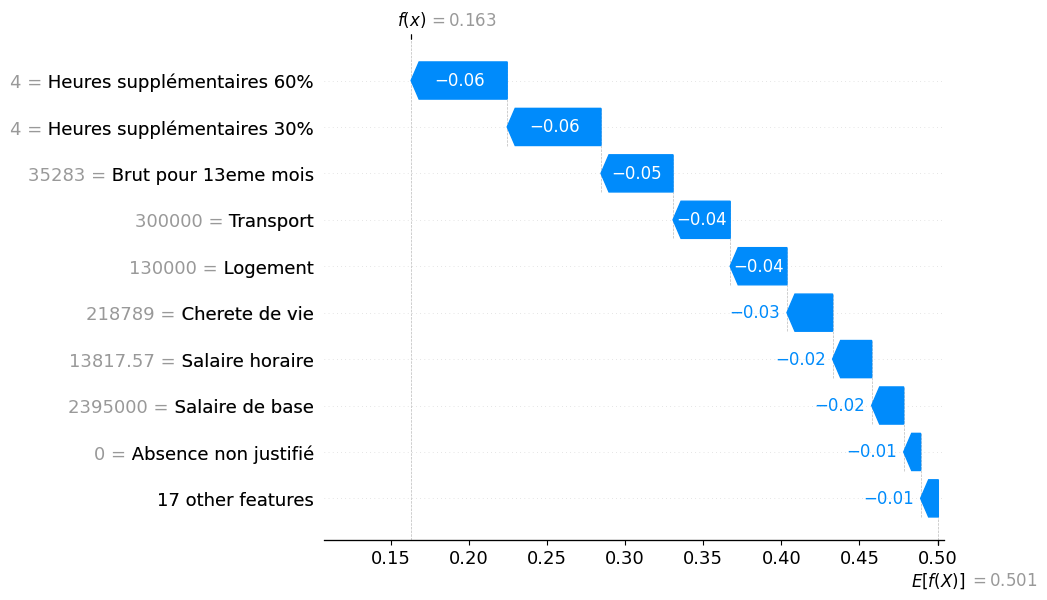

In [ ]:
shap.plots.waterfall(shap_values[:, :, 1][55])

## Saving models

In [ ]:
joblib.dump(error_model_rf, 'surrogate_model.joblib')
surrogate_model = joblib.load('surrogate_model.joblib')

joblib.dump(model_if, 'isolation_forest_model.joblib')
loaded_model = joblib.load('isolation_forest_model.joblib')

joblib.dump(gb_model, 'gradient_boosting_model.joblib')
loaded_gb_model = joblib.load('gradient_boosting_model.joblib') 

In [ ]:
# Retrieve the transformed output feature names
iso_features = loaded_model.feature_names_in_
gb_features = loaded_gb_model.feature_names_in_
rf_features = surrogate_model.feature_names_in_

print("Isolation Forest Features:", list(iso_features))
print("Gradient Boosting Features:", list(gb_features))
print("Random Forest Surrogate Model Features:", list(rf_features))


Isolation Forest Features: ['Relative Residual', 'Valeur trentième', 'Transport', 'Présence', 'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement', 'Heures supplémentaires 60%', 'Salaire horaire', 'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%', 'Heures supplémentaires 30%', 'Cherete de vie', 'Heures Majorée 20%', 'Rappel -Heures supplément.65%', 'Absence non justifié', 'Primes', 'Divers Prêts', "Rappel Prime d'ancienneté", 'Avance sur salaires Prestatair', 'Prorata Renumeration precedent', 'Frais Medicaux', 'Jour Férié 100%', 'Remboursement trop perçu', 'Acompte sur Salaire', 'Rappel Salaire en Plus']
Gradient Boosting Features: ['Valeur trentième', 'Transport', 'Présence', 'Heures Supplementaire  65%', 'Brut pour 13eme mois', 'Logement', 'Heures supplémentaires 60%', 'Salaire horaire', 'Rappel Heures supplément.30%', 'Rappel -Heures supplément.60%', 'Heures supplémentaires 30%', 'Cherete de vie', 'Salaire de base', 'Heures Majorée 20%', 'Rappel -Heures sup

In [ ]:
df_2026=pd.read_csv("data2026.csv",encoding='latin1')

In [ ]:
df_2026.columns

Index(['ï»¿CSAL_NOSAL', 'DATE', 'INTITULE', 'VALEUR'], dtype='object')

In [ ]:
df_2026_pivot=df_2026.pivot(index=['ï»¿CSAL_NOSAL','DATE'], columns='INTITULE', values='VALEUR').reset_index()

In [ ]:
df_2026_pivot.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1429 entries, 0 to 1428
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ï»¿CSAL_NOSAL                1429 non-null   int64  
 1   DATE                         1429 non-null   object 
 2   Brut                         1429 non-null   float64
 3   Cherete de vie               1339 non-null   float64
 4   Heures Supplementaire  65%   344 non-null    float64
 5   Heures supplÃ©mentaires 30%  521 non-null    float64
 6   Heures supplÃ©mentaires 60%  514 non-null    float64
 7   Logement                     1323 non-null   float64
 8   Net Ã  payer                 1429 non-null   float64
 9   Prime de Ramadan             1429 non-null   float64
 10  Salaire de base              1429 non-null   float64
 11  Transport                    1307 non-null   float64
dtypes: float64(10), int64(1), object(1)
memory usage: 134.1+ KB


In [ ]:
df_2026_pivot.to_csv("df_2026_pivot.csv", index=False)